# EDA for Runs with Metrics

In [4]:
import os

# Print current working directory
print(os.getcwd())

# Change to your desired directory
os.chdir('/Users/svasquez/driblab/dl-vision')
print(os.getcwd())

/Users/svasquez/driblab/dl-vision
/Users/svasquez/driblab/dl-vision


In [5]:
import json
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np

# Load Data

In [73]:
runs_path = f"stats/obso/datasets/test_filtered_runs_recalculated.jsonl"
runs_path = f"stats/obso/datasets/test_filtered_runs_recalculated_v2.jsonl"


# Load the JSONL file
runs = []
with open(runs_path, 'r') as f:
    for line in f:
        runs.append(json.loads(line))


print(runs[0])
print(f"Run Length: {len(runs)}")

{'match_id': 622090, 'run_id': '622090_12', 'team_id': 4273, 'player_id': 193811, 'ball_carrier_id_start': 1530469, 'ball_carrier_id_end': 1329724, 'start_frame': 2162, 'end_frame': 2186, 'start_timestamp': 215.74, 'end_timestamp': 218.14, 'period': 1, 'runner_info': {'start_position': {'x': 85.21, 'y': 34.86}, 'positions': [{'x': 85.21, 'y': 34.86, 'frame': 2162, 'period': 1}], 'metrics': {'xR_start': 0.4490000009536743, 'xR_end': 0.5879999995231628, 'PC_start': 0.912, 'PC_end': 0.909, 'xG_start': 0.0, 'xG_end': 0.0, 'OBSO_start': None, 'OBSO_end': None}, 'end_position': {'x': 95.62, 'y': 42.24}}, 'possession': {'start_team': '4273', 'end_team': '4273'}, 'off_ball_teammates': [{'player_id': 1166785, 'start_position': {'x': 58.65, 'y': 37.12}, 'end_position': {'x': 70.12, 'y': 33.48}, 'metrics': {'xR_start': 0.34200000762939453, 'xR_end': 0.27300000190734863, 'PC_start': 0.224, 'PC_end': 0.785, 'xG_start': 0.0, 'xG_end': 0.0, 'OBSO_start': None, 'OBSO_end': None}}, {'player_id': 157507

### Load t_player and t_team dfs 

In [74]:
t_player_data = pd.read_csv("/Users/svasquez/AWS_PC/t_player_top5_leagues.csv")
t_team_data = pd.read_csv("/Users/svasquez/AWS_PC/t_team_data.csv")


## Get unique match ids

In [75]:
match_ids = set()

for run in runs:
    match_ids.add(run['match_id'])

print(match_ids)

print(len(match_ids))



{622090, 622092, 622093, 622094, 622096, 622098, 622100, 622101, 622102, 622104, 622106, 622107, 622109, 622112, 622117, 622118, 622121, 622122, 622123, 622124, 622125, 622126, 622128, 622129, 622130, 622133, 622135, 622136, 622139, 622142, 622144, 622146, 622148, 622149, 622150, 622151, 622152, 622153, 622154, 622155, 622156, 622157, 622158, 622159, 622160, 622161, 622162, 622163, 622164, 622165, 622166, 622177, 622178, 622180, 622181, 622182, 622183, 622184, 622185, 622186, 622187, 622188, 622189, 622190, 622191, 622192, 622193, 622194, 622195, 622196, 622197, 622198, 622199, 622202, 622204, 622205, 622207, 622208, 622209, 622211, 622212, 622214, 622216, 622217, 622218, 622220, 622221, 622222, 622223, 622224, 622225, 622226, 622227, 622228, 622229, 622230, 622231, 622233, 622234, 622235, 622236, 622237, 622238, 622239, 622240, 622241, 622242, 622243, 622244, 622245, 622246, 622247, 622248, 622249, 622250, 622251, 622252, 622253, 622254, 622255, 622258, 622259, 622260, 622261, 622263,

## Get distribution of runs by period

len(periods) 13169


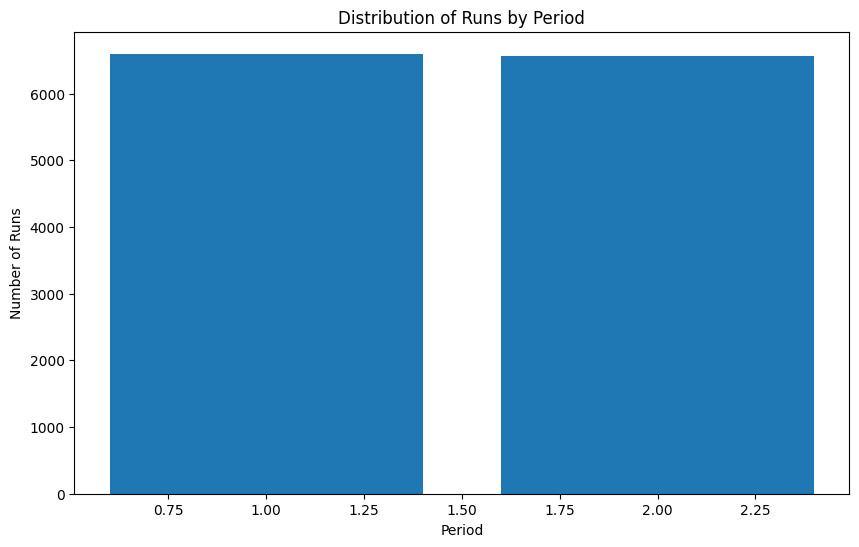

In [76]:
periods = []



for run in runs:
    period = run['period']

    periods.append(period)

print(f"len(periods) {len(periods)}")

# Count frequency of each period
period_counts = pd.Series(periods).value_counts()



# Plot period distribution
plt.figure(figsize=(10,6))
plt.bar(period_counts.index, period_counts.values)
plt.title('Distribution of Runs by Period')
plt.xlabel('Period')
plt.ylabel('Number of Runs')
plt.show()

# Runner EDA

In [77]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Flatten into a pandas DataFrame
def extract_run_info(run):
    runner = run['runner_info']
    start_x, start_y = runner['start_position']['x'], runner['start_position']['y']
    end_x, end_y = runner['end_position']['x'], runner['end_position']['y']
    dx = end_x - start_x
    dy = end_y - start_y
    distance = (dx**2 + dy**2)**0.5
    duration = run['end_timestamp'] - run['start_timestamp']
    speed = distance / duration if duration > 0 else 0

    att_goal_x = run['att_goal'][0]
    att_goal_y = run['att_goal'][1]
    

    


    return {
        "match_id": run["match_id"],
        "run_id": run["run_id"],
        "team_id": run["team_id"],
        "player_id": run["player_id"],
        "start_frame": run["start_frame"],
        "end_frame": run["end_frame"],
        "start_x": start_x,
        "start_y": start_y,
        "end_x": end_x,
        "end_y": end_y,
        "duration": duration,
        "distance": distance,
        "speed": speed,
        "period": run["period"],
        "xR_start": runner["metrics"]["xR_start"],
        "xR_end": runner["metrics"]["xR_end"],
        "PC_start": runner["metrics"]["PC_start"],
        "PC_end": runner["metrics"]["PC_end"],
        "xG_start": runner["metrics"]["xG_start"],
        "xG_end": runner["metrics"]["xG_end"],
        "att_goal_x": att_goal_x,
        "att_goal_y": att_goal_y
    }



df = pd.DataFrame([extract_run_info(r) for r in runs])
# df = pd.DataFrame([extract_run_info(r) for r in filtered_runs])

print(f"LENGTH: {len(df)}")

df.columns



LENGTH: 13169


Index(['match_id', 'run_id', 'team_id', 'player_id', 'start_frame',
       'end_frame', 'start_x', 'start_y', 'end_x', 'end_y', 'duration',
       'distance', 'speed', 'period', 'xR_start', 'xR_end', 'PC_start',
       'PC_end', 'xG_start', 'xG_end', 'att_goal_x', 'att_goal_y'],
      dtype='object')

In [78]:
# remove any runs with negative metrics

print(len(df))
df = df[df['xR_start'] >= 0]
df = df[df['xR_end'] >= 0]
df = df[df['PC_start'] >= 0]
df = df[df['PC_end'] >= 0]
df = df[df['xG_start'] >= 0]
df = df[df['xG_end'] >= 0]


print(len(df))

13169
13168


### Join the t_player_data with the Runner's DF

In [79]:
df = df.merge(t_player_data, on='player_id', how='left')

df.head(10)


,match_id,run_id,team_id_x,player_id,start_frame,end_frame,start_x,start_y,end_x,end_y,...,xG_start,xG_end,att_goal_x,att_goal_y,team_id_y,plyr_name,team_name,season_id,season_name,plyr_position
0,622090,622090_12,4273,193811,2162,2186,85.21,34.86,95.62,42.24,...,0.0,0.0,105,34,4273.0,Aritz Elustondo,Real Sociedad,817531.0,ESP I 2024,DC
1,622090,622090_14,4273,1329663,2216,2240,68.97,4.23,78.12,20.27,...,0.0,0.0,105,34,4273.0,Javier Lopez,Real Sociedad,817531.0,ESP I 2024,DL
2,622090,622090_15,4275,1248194,2412,2430,36.12,64.91,25.17,64.97,...,0.0,0.0,0,34,4275.0,Oscar Valentin,Rayo Vallecano,817531.0,ESP I 2024,DMC
3,622090,622090_44,4273,1329724,5804,5818,76.77,30.92,84.08,31.60,...,0.0,0.0,105,34,4273.0,Jon Pacheco,Real Sociedad,817531.0,ESP I 2024,DC
4,622090,622090_49,4275,1268026,6280,6294,31.21,20.86,20.34,25.86,...,0.0,0.0,0,34,4275.0,Andrei Ratiu,Rayo Vallecano,817531.0,ESP I 2024,DR
5,622090,622090_59,4275,1248194,8568,8584,37.82,4.69,33.30,12.28,...,0.0,0.0,0,34,4275.0,Oscar Valentin,Rayo Vallecano,817531.0,ESP I 2024,DMC
6,622090,622090_120,4273,273054,15316,15383,69.38,11.98,70.16,23.25,...,0.0,0.0,105,34,4273.0,Mikel Oyarzabal,Real Sociedad,817531.0,ESP I 2024,FW
7,622090,622090_121,4273,1530469,15326,15383,64.46,2.90,76.17,33.46,...,0.0,0.0,105,34,4273.0,Beñat Turrientes,Real Sociedad,817531.0,ESP I 2024,DMC
8,622090,622090_122,4273,1329663,15316,15383,72.08,0.49,79.60,15.59,...,0.0,0.0,105,34,4273.0,Javier Lopez,Real Sociedad,817531.0,ESP I 2024,DL
9,622090,622090_162,4275,81306,19640,19658,45.52,41.70,28.51,61.89,...,0.0,0.0,0,34,4275.0,Adrian Embarba,Rayo Vallecano,817531.0,ESP I 2024,AMR


## Plot all the runs

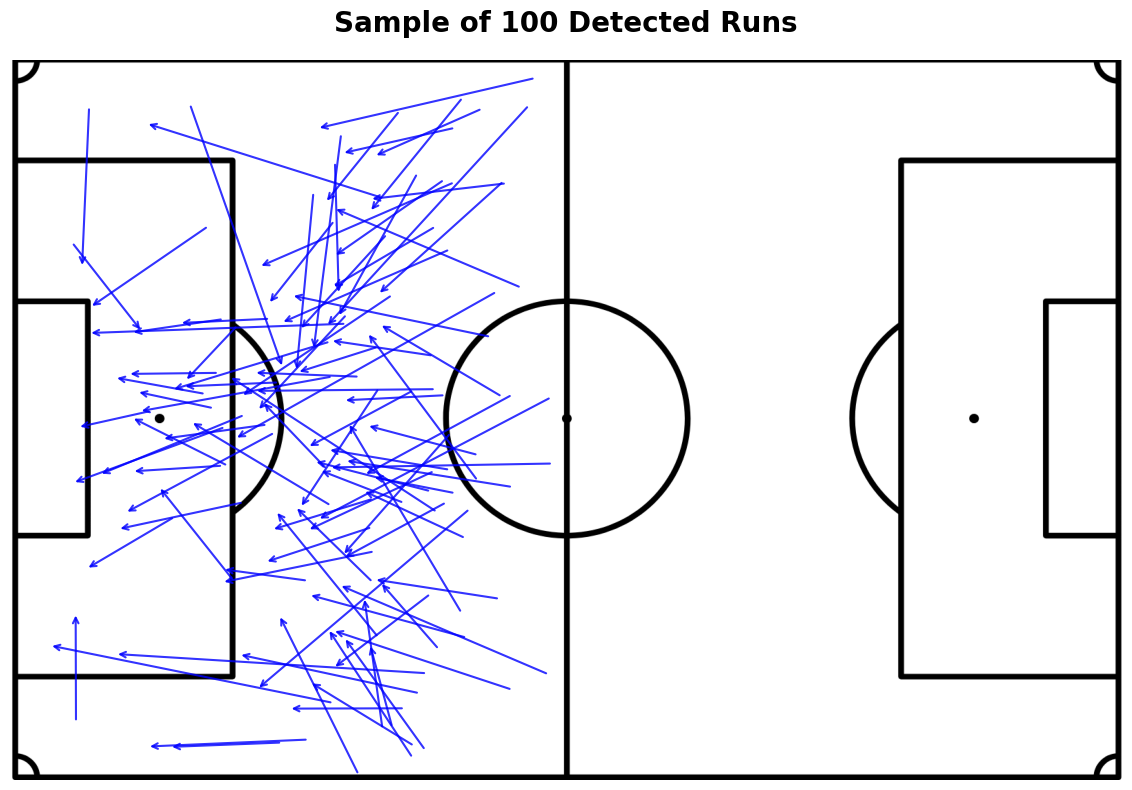

In [81]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def plot_simple_runs_with_pitch(df, title="Sample of 100 Detected Runs", pitch_path=None):
    """Plots simple arrows representing runs over a football pitch background."""
    fig, ax = plt.subplots(figsize=(14, 8))
    
    # Load and show the pitch background image
    if pitch_path:
        img = mpimg.imread(pitch_path)
        ax.imshow(img, extent=[0, 105, 68, 0], aspect='auto')  # Set correct field size and invert Y

    # Plot each run
    for _, row in df.iterrows():
        start_x, start_y = row['start_x'], row['start_y']
        end_x, end_y = row['end_x'], row['end_y']
        att_goal_x = row['att_goal_x']

        # Flip if attacking right to left
        if att_goal_x == 105:
            start_x, start_y = 105 - start_x, 68 - start_y
            end_x, end_y = 105 - end_x, 68 - end_y
        
        ax.annotate(
            "", 
            xy=(end_x, end_y), 
            xytext=(start_x, start_y),
            arrowprops=dict(arrowstyle="->", color='blue', lw=1.5, alpha=0.8)
        )

    # Set field dimensions
    ax.set_xlim(0, 105)
    ax.set_ylim(0, 68)
    ax.set_aspect('equal')
    ax.invert_yaxis()
    
    # Remove axes
    ax.axis('off')
    
    # Set title
    plt.title(title, fontsize=20, weight='bold', pad=20)
    
    plt.tight_layout()
    plt.show()

# Call it like this:

football_pitch_path = "/Users/svasquez/AWS_PC/Football_pitch_white.png"
plot_simple_runs_with_pitch(mini_df, pitch_path=football_pitch_path)


### Get Players with Most Runs

In [82]:

# Group by 'player_id' and count runs
run_counts = df.groupby('player_id')['run_id'].count().reset_index(name='run_count')

# Sort by run count
run_counts = run_counts.sort_values(by='run_count', ascending=False)

# Merge with player data
run_counts = run_counts.merge(t_player_data, on='player_id', how='left')

run_counts.head(10)


,player_id,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
0,1216616,161,4279.0,Raphinha,FC Barcelona,817531.0,ESP I 2024,AML
1,191594,123,4270.0,Inaki Williams,Athletic Club,817531.0,ESP I 2024,AMR
2,1155227,113,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
3,1158830,104,4270.0,Alex Berenguer,Athletic Club,817531.0,ESP I 2024,AMC
4,69936,101,4279.0,Robert Lewandowski,FC Barcelona,817531.0,ESP I 2024,FW
5,20,101,1.0,Antoine Griezmann,Atletico Madrid,817531.0,ESP I 2024,FW
6,1533082,100,4270.0,Nico Williams,Athletic Club,817531.0,ESP I 2024,AML
7,1155702,97,20079.0,Vedat Muriqi,RCD Mallorca,817531.0,ESP I 2024,FW
8,1171076,96,2.0,Hugo Duro,Valencia,817531.0,ESP I 2024,FW
9,1242412,88,1.0,Julian Alvarez,Atletico Madrid,817531.0,ESP I 2024,FW


### Distribution of Runs by players

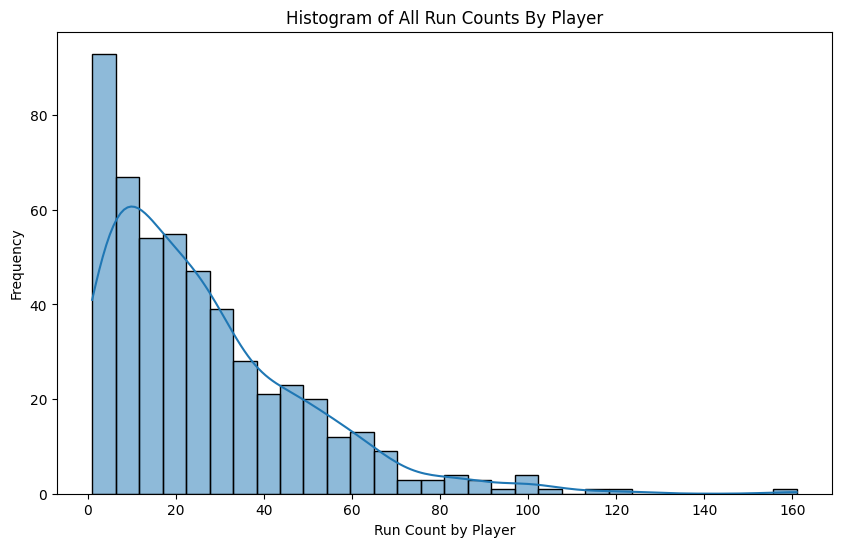

In [83]:
# Create a histogram of all run counts
plt.figure(figsize=(10, 6))
sns.histplot(run_counts['run_count'], bins=30, kde=True)
plt.title("Histogram of All Run Counts By Player")
plt.xlabel("Run Count by Player")
plt.ylabel("Frequency")
plt.show()


### Calculate OBSO added by runner

In [84]:
import numpy as np


def calc_OBSO(xR, PC, xG):
    return xR * PC * xG


In [85]:
# Calculate total changes for each metric
df["xR_added_runner"] = df["xR_end"] - df["xR_start"]
df["PC_added_runner"] = df["PC_end"] - df["PC_start"] 
df["xG_added_runner"] = df["xG_end"] - df["xG_start"]
df['OBSO_start'] = calc_OBSO(df['xR_start'], df['PC_start'], df['xG_start'])
df['OBSO_end'] = calc_OBSO(df['xR_end'], df['PC_end'], df['xG_end'])
df['OBSO_added'] = df['OBSO_end'] - df['OBSO_start']

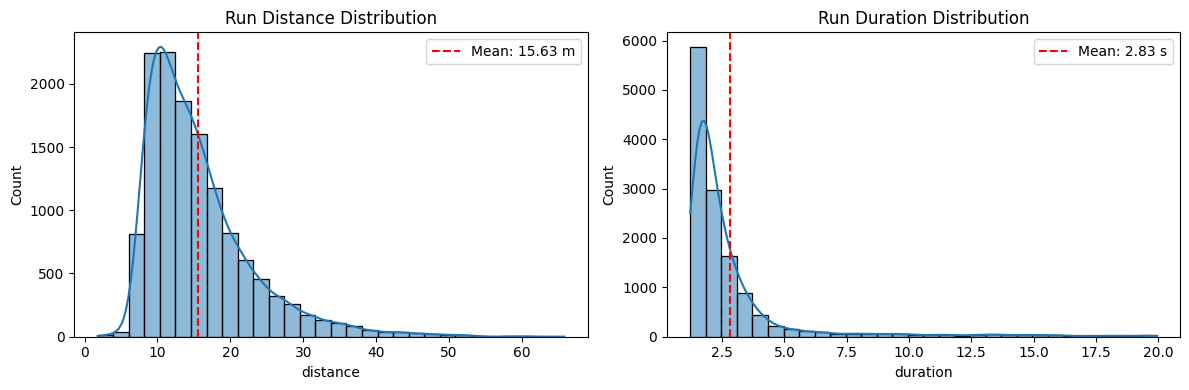

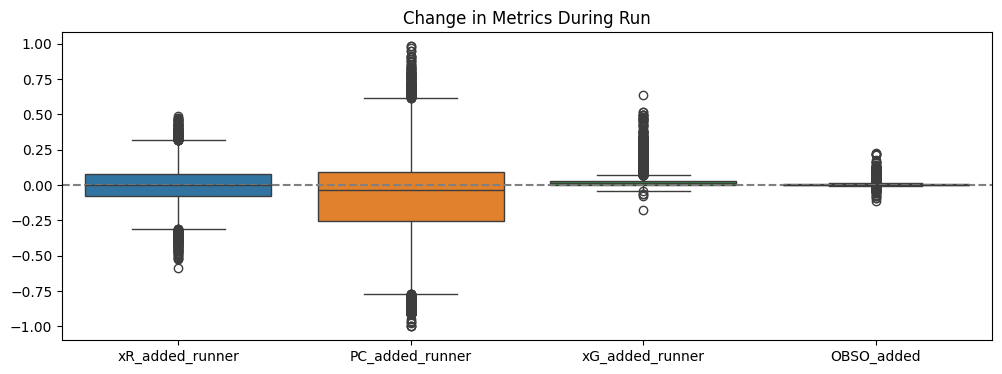

In [86]:


# --- DISTRIBUTIONS ---
plt.figure(figsize=(12, 4))

# Distance Distribution
plt.subplot(1, 2, 1)
sns.histplot(df["distance"], bins=30, kde=True)
plt.axvline(df["distance"].mean(), color='red', linestyle='--', label=f'Mean: {df["distance"].mean():.2f} m')
plt.title("Run Distance Distribution")
plt.legend()

# Duration Distribution
plt.subplot(1, 2, 2)
sns.histplot(df["duration"], bins=30, kde=True)
plt.axvline(df["duration"].mean(), color='red', linestyle='--', label=f'Mean: {df["duration"].mean():.2f} s')
plt.title("Run Duration Distribution")
plt.legend()

plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 4))
sns.boxplot(data=df[["xR_added_runner", "PC_added_runner", "xG_added_runner", "OBSO_added"]])
plt.title("Change in Metrics During Run")
plt.axhline(0, color="gray", linestyle="--")
plt.show()


## Get the top run with runner's change in xG, xR and PC

In [87]:
mean_xR = df['xR_added_runner'].mean()
mean_PC = df['PC_added_runner'].mean()
mean_xG = df['xG_added_runner'].mean()
OBSO_mean = df['OBSO_added'].mean()

print(f"Mean xR: {mean_xR}")
print(f"Mean PC: {mean_PC}")
print(f"Mean xG: {mean_xG}")
print(f"Mean OBSO: {OBSO_mean}")

Mean xR: -0.00024043098499462062
Mean PC: -0.06926291008505467
Mean xG: 0.03068803159173755
Mean OBSO: 0.005374770141529275


## Show distribution for xR, PC, xG and OBSO

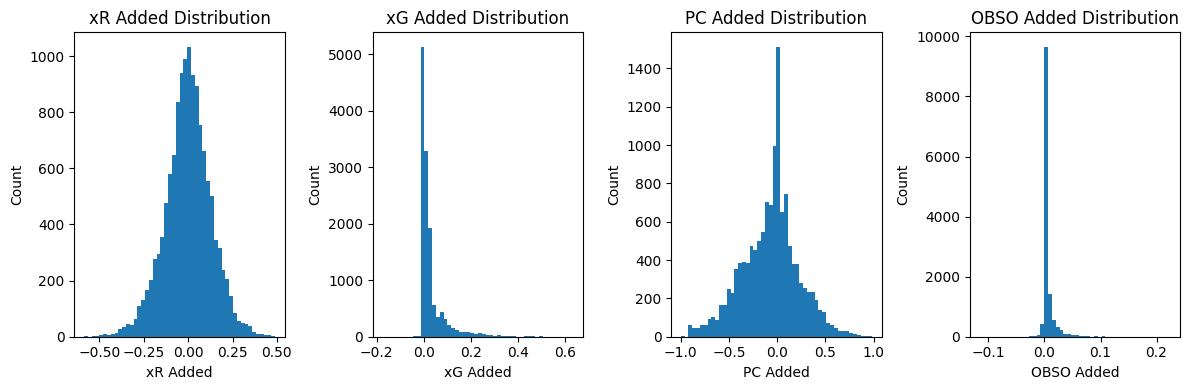

In [88]:
# Create histograms for each metric
plt.figure(figsize=(12, 4))

plt.subplot(141)
plt.hist(df['xR_added_runner'], bins=50)
plt.title('xR Added Distribution')
plt.xlabel('xR Added')
plt.ylabel('Count')

plt.subplot(142)
plt.hist(df['xG_added_runner'], bins=50)
plt.title('xG Added Distribution') 
plt.xlabel('xG Added')
plt.ylabel('Count')

plt.subplot(143)
plt.hist(df['PC_added_runner'], bins=50)
plt.title('PC Added Distribution')
plt.xlabel('PC Added')
plt.ylabel('Count')

plt.subplot(144)
plt.hist(df['OBSO_added'], bins=50)
plt.title('OBSO Added Distribution')
plt.xlabel('OBSO Added')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


## Test Correlation between xR and PC

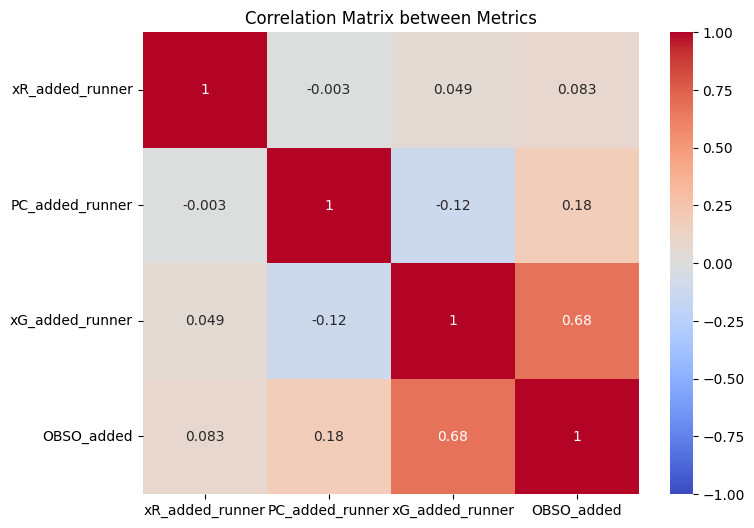

In [90]:
# Calculate correlations between metrics
corr_xR_PC = df['xR_start'].corr(df['PC_start'])
corr_xR_xG = df['xR_start'].corr(df['xG_start']) 
corr_PC_xG = df['PC_start'].corr(df['xG_start'])
corr_OBSO_xR = df['OBSO_start'].corr(df['xR_start'])
corr_OBSO_PC = df['OBSO_start'].corr(df['PC_start'])
corr_OBSO_xG = df['OBSO_start'].corr(df['xG_start'])

# Create correlation matrix plot
plt.figure(figsize=(8, 6))
corr_matrix = df[['xR_added_runner', 'PC_added_runner', 'xG_added_runner', 'OBSO_added']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix between Metrics")
plt.show()



# Top run with more OBSO

In [91]:
df.columns

Index(['match_id', 'run_id', 'team_id_x', 'player_id', 'start_frame',
       'end_frame', 'start_x', 'start_y', 'end_x', 'end_y', 'duration',
       'distance', 'speed', 'period', 'xR_start', 'xR_end', 'PC_start',
       'PC_end', 'xG_start', 'xG_end', 'att_goal_x', 'att_goal_y', 'team_id_y',
       'plyr_name', 'team_name', 'season_id', 'season_name', 'plyr_position',
       'xR_added_runner', 'PC_added_runner', 'xG_added_runner', 'OBSO_start',
       'OBSO_end', 'OBSO_added'],
      dtype='object')

In [92]:
top_runs_df =df.nlargest(10, "OBSO_added")

# Keep only relevant columns
top_runs_df = top_runs_df[["match_id", "run_id", 'plyr_name',"team_name", "xR_added_runner", "PC_added_runner", "xG_added_runner", "OBSO_added"]]

top_runs_df


,match_id,run_id,plyr_name,team_name,xR_added_runner,PC_added_runner,xG_added_runner,OBSO_added
8751,622292,622292_790,Kike Garcia,Deportivo Alaves,0.301,0.709,0.495,0.224787
1618,622148,622148_234,Raul Garcia,Osasuna,-0.003,0.110,0.518,0.221359
5861,622244,622244_92,Borja Iglesias,Celta de Vigo,0.177,0.952,0.482,0.218130
7825,622278,622278_293,Kylian Mbappe,Real Madrid,-0.113,0.092,0.495,0.217800
6982,622265,622265_50,Jon Aramburu,Real Sociedad,-0.170,0.489,0.519,0.213309
6419,622252,622252_123,Carlos Romero,Espanyol,-0.051,0.290,0.456,0.175621
8324,622288,622288_30,NaN,NaN,0.068,-0.146,0.472,0.162564
12492,622364,622364_198,Takefusa Kubo,Real Sociedad,0.094,0.418,0.342,0.162526
3572,622193,622193_333,NaN,NaN,0.293,0.499,0.331,0.161592
12559,638259,638259_14,NaN,NaN,0.056,0.360,0.339,0.155472


# Team Wide Runs EDA

In [93]:
# Create a DataFrame to hold team-wide deltas
rows = []

for run in runs:
    run_id = run['run_id']
    match_id = run['match_id']
    period = run['period']
    team_id = run['team_id']

    # Get run start and end
    run_start = run['runner_info']['start_position']['x'] , run['runner_info']['start_position']['y']
    run_end = run['runner_info']['end_position']['x'] , run['runner_info']['end_position']['y']

    # Get distance

    dx = run_end[0] - run_start[0]
    dy = run_end[1] - run_start[1]
    distance = (dx**2 + dy**2)**0.5

    

    # if distance < 10: continue

    # Runner data

    runner_id = run['player_id']

    # Runner metrics
    runner_metrics = run['runner_info']['metrics']
    xR_start = runner_metrics['xR_start']
    xR_end = runner_metrics['xR_end']
    PC_start = runner_metrics['PC_start']
    PC_end = runner_metrics['PC_end']
    xG_start = runner_metrics['xG_start']
    xG_end = runner_metrics['xG_end']

    # Runners OBSO
    OBSO_start = calc_OBSO(xR_start, PC_start, xG_start)
    OBSO_end = calc_OBSO(xR_end, PC_end, xG_end)
    OBSO_delta = OBSO_end - OBSO_start


    # get ball carrier

    ball_carrier_id_start = run['ball_carrier_id_start']
    ball_carrier_id_end = run['ball_carrier_id_end']



    sum_OBSO = 0  + OBSO_delta

    sum_xR_delta = 0 + (xR_end - xR_start)
    sum_PC_delta = 0 + (PC_end - PC_start)
    sum_xG_delta = 0 + (xG_end - xG_start)

    for teammate in run.get('off_ball_teammates', []):

        metrics = teammate.get('metrics', {})

        # if teammate is the ball carrier
        if teammate['player_id'] == ball_carrier_id_start:

            xR_start = 0
            PC_start = 0
            xG_start = 0

        else:
            # Get start metrics
            xR_start = metrics.get('xR_start', 0) or 0
            PC_start = metrics.get('PC_start', 0) or 0
            xG_start = metrics.get('xG_start', 0) or 0

        if teammate['player_id'] == ball_carrier_id_end:
            xR_end = 0
            PC_end = 0
            xG_end = 0

        else:
            # Get end metrics
            xR_end = metrics.get('xR_end', 0) or 0
            PC_end = metrics.get('PC_end', 0) or 0
            xG_end = metrics.get('xG_end', 0) or 0

        # xR Added team
        xR_added_team = xR_end - xR_start
        sum_xR_delta += xR_added_team

        PC_added_team = PC_end - PC_start
        sum_PC_delta += PC_added_team

        xG_added_team = xG_end - xG_start
        sum_xG_delta += xG_added_team

        OBSO_start = calc_OBSO(xR_start, PC_start, xG_start)
        OBSO_end = calc_OBSO(xR_end, PC_end, xG_end)
        OBSO_delta = OBSO_end - OBSO_start
        

        sum_OBSO += OBSO_delta



    rows.append({
        "match_id": match_id,
        "run_id": run_id,
        'player_id': runner_id,
        "team_id": team_id,
        "period": period,
        "xR_added_team": sum_xR_delta,
        "PC_added_team": sum_PC_delta,
        "xG_added_team": sum_xG_delta,
        "OBSO_added_team": sum_OBSO
    })

team_wide_df = pd.DataFrame(rows)

# Merge with t_player_data
team_wide_df = team_wide_df.merge(t_player_data, on='player_id', how='left')

team_wide_df

,match_id,run_id,player_id,team_id_x,period,xR_added_team,PC_added_team,xG_added_team,OBSO_added_team,team_id_y,plyr_name,team_name,season_id,season_name,plyr_position
0,622090,622090_12,193811,4273,1,-1.622,0.769,0.000000e+00,0.000000,4273.0,Aritz Elustondo,Real Sociedad,817531.0,ESP I 2024,DC
1,622090,622090_14,1329663,4273,1,-0.132,2.469,0.000000e+00,0.000000,4273.0,Javier Lopez,Real Sociedad,817531.0,ESP I 2024,DL
2,622090,622090_15,1248194,4275,1,-0.256,-0.302,-8.000000e-03,-0.008366,4275.0,Oscar Valentin,Rayo Vallecano,817531.0,ESP I 2024,DMC
3,622090,622090_44,1329724,4273,1,-0.039,0.617,0.000000e+00,0.000000,4273.0,Jon Pacheco,Real Sociedad,817531.0,ESP I 2024,DC
4,622090,622090_49,1268026,4275,1,-0.191,0.449,-2.000000e-03,-0.001106,4275.0,Andrei Ratiu,Rayo Vallecano,817531.0,ESP I 2024,DR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13164,638268,638268_368,1293836,4266,2,0.317,0.634,5.040000e-01,0.162173,4266.0,Johnny Cardoso,Real Betis,817531.0,ESP I 2024,DMC
13165,638268,638268_369,270420,4266,2,0.431,-0.788,4.600000e-01,0.090140,4266.0,Pablo Fornals,Real Betis,817531.0,ESP I 2024,MR
13166,638268,638268_375,270420,4266,2,-0.696,-0.231,-6.938894e-18,-0.004445,4266.0,Pablo Fornals,Real Betis,817531.0,ESP I 2024,MR
13167,638268,638268_378,270420,4266,2,-0.055,-0.382,-8.000000e-03,-0.003619,4266.0,Pablo Fornals,Real Betis,817531.0,ESP I 2024,MR


## Save Team Wide OBSO added

In [94]:
output_path = "stats/obso/datasets/team_wide_obso_added_v2.csv"
team_wide_df.to_csv(output_path, index=False)

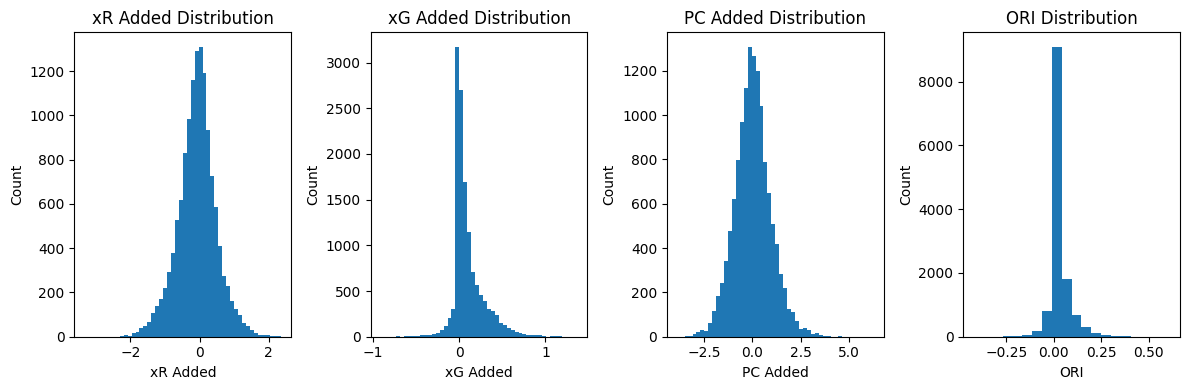

In [95]:
# Create histograms for each metric
plt.figure(figsize=(12, 4))

plt.subplot(141)
plt.hist(team_wide_df['xR_added_team'], bins=50)
plt.title('xR Added Distribution')
plt.xlabel('xR Added')
plt.ylabel('Count')

plt.subplot(142)
plt.hist(team_wide_df['xG_added_team'], bins=50)
plt.title('xG Added Distribution') 
plt.xlabel('xG Added')
plt.ylabel('Count')

plt.subplot(143)
plt.hist(team_wide_df['PC_added_team'], bins=50)
plt.title('PC Added Distribution')
plt.xlabel('PC Added')
plt.ylabel('Count')

plt.subplot(144)
plt.hist(team_wide_df['OBSO_added_team'], bins=20)
plt.title('ORI Distribution')
plt.xlabel('ORI')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


In [29]:

print("\n📊 Basic stats per metric:")
print(team_wide_df[["xR_added_team", "PC_added_team", "xG_added_team", "OBSO_added_team"]].describe())


📊 Basic stats per metric:
       xR_added_team  PC_added_team  xG_added_team  OBSO_added_team
count   13169.000000   13169.000000   13169.000000     13169.000000
mean       -0.073191       0.028762       0.107388         0.026435
std         0.558850       0.946292       0.195366         0.061725
min        -3.329000      -3.917000      -0.953000        -0.510354
25%        -0.393000      -0.568000       0.000000         0.000000
50%        -0.057000       0.002000       0.046000         0.009020
75%         0.252000       0.588000       0.167000         0.039090
max         2.364000       6.298000       3.076000         1.568109


### Test Normality with Q-Q plots

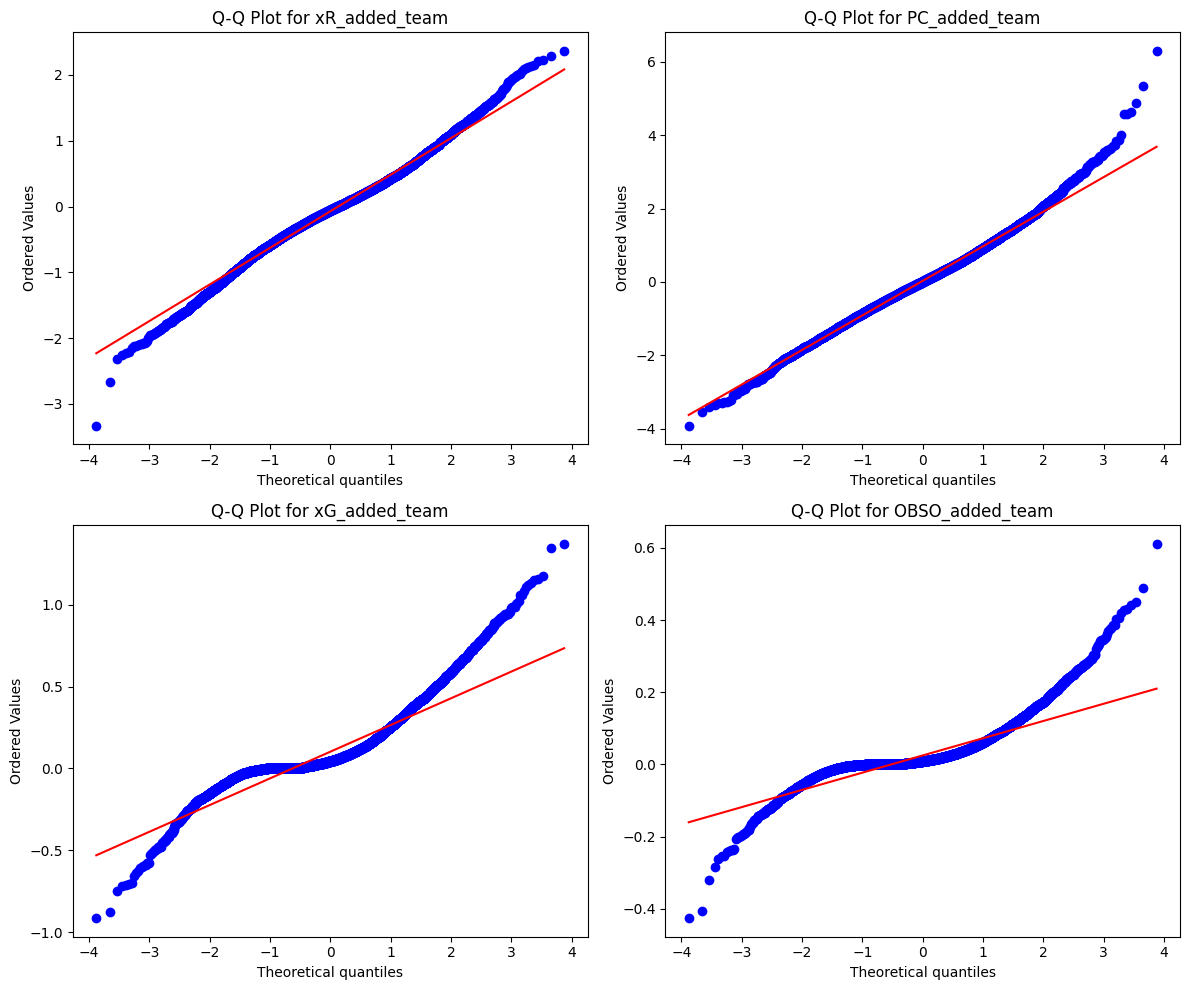

In [123]:
import scipy.stats as stats

# Test normality with Q-Q plots for each metric
metrics = ['xR_added_team', 'PC_added_team', 'xG_added_team', 'OBSO_added_team']
plt.figure(figsize=(12, 10))

for i, metric in enumerate(metrics, 1):
    plt.subplot(2, 2, i)
    stats.probplot(team_wide_df[metric], dist="norm", plot=plt)
    plt.title(f'Q-Q Plot for {metric}')

plt.tight_layout()
plt.show()


## Test Correlation in Team wide OBSO

In [98]:
corr_matrix.index = ['xR_added_team', 'PC_added_team', 'xG_added_team', 'ORI']



In [99]:
corr_matrix

,xR_added_runner,PC_added_runner,xG_added_runner,OBSO_added
xR_added_team,1.000000,-0.003032,0.049042,0.082897
PC_added_team,-0.003032,1.000000,-0.117862,0.181966
xG_added_team,0.049042,-0.117862,1.000000,0.679442
ORI,0.082897,0.181966,0.679442,1.000000


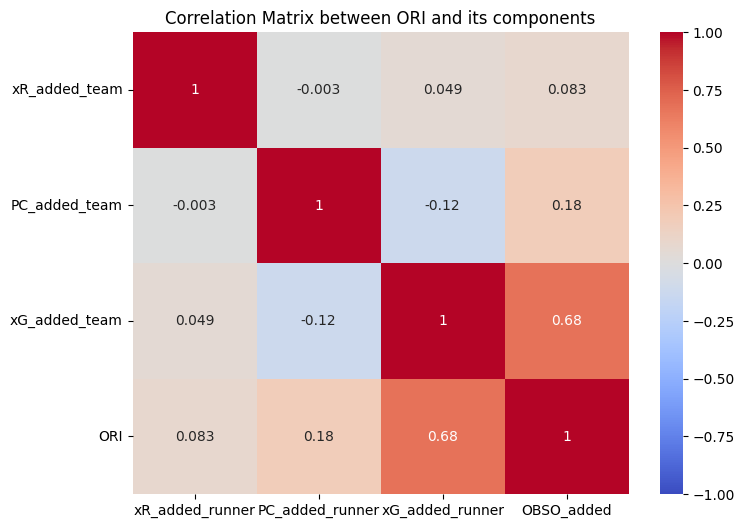

In [100]:

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, xticklabels=1, yticklabels=1)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.title("Correlation Matrix between ORI and its components")
plt.show()

In [101]:

# Create correlation matrix plot
plt.figure(figsize=(8, 6))
corr_matrix = team_wide_df[['xR_added_team', 'PC_added_team', 'xG_added_team', 'OBSO_added_team']].corr()

# corr_matrix['ORI'] = corr_matrix.pop('OBSO_added_team')




<Figure size 800x600 with 0 Axes>

## Disect OBSO by component

### By xR

In [34]:
# Get the top players based on xR added

agg_xR_team = team_wide_df.groupby('player_id')['xR_added_team'].sum().reset_index()

agg_xR_team = agg_xR_team.sort_values(by='xR_added_team', ascending=False)

# Merge with run counts
agg_xR_team = agg_xR_team.merge(run_counts, on='player_id', how='left')


print(f"LENGTH: {len(agg_xR_team)}")
# Filter out players with less than 10 runs
agg_xR_team = agg_xR_team[agg_xR_team['run_count'] >= 30]

print(f"LENGTH: {len(agg_xR_team)}")

agg_xR_team.head(10)

LENGTH: 503
LENGTH: 171


,player_id,xR_added_team,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
0,1158803,7.973000,38,4275.0,Sergi Guardiola,Rayo Vallecano,817531.0,ESP I 2024,FW
2,1159916,5.503001,30,4267.0,Lucas Torro,Osasuna,817531.0,ESP I 2024,MC
7,279953,4.532000,42,4273.0,Igor Zubeldia,Real Sociedad,817531.0,ESP I 2024,DC
9,773,3.751000,39,4263.0,Marcos Alonso,Celta de Vigo,817531.0,ESP I 2024,DC
10,269513,3.699000,45,4269.0,Mamadou Sylla,Valladolid,817531.0,ESP I 2024,FW
16,1646482,3.465001,33,4263.0,Hugo Sotelo,Celta de Vigo,817531.0,ESP I 2024,MC
20,1268026,2.844000,66,4275.0,Andrei Ratiu,Rayo Vallecano,817531.0,ESP I 2024,DR
22,1248950,2.676000,36,4275.0,Randy Nteka,Rayo Vallecano,817531.0,ESP I 2024,FW
25,1707759,2.493001,43,4263.0,Hugo Álvarez,Celta de Vigo,817531.0,ESP I 2024,DML
27,1305538,2.358000,56,20079.0,Samu Costa,RCD Mallorca,817531.0,ESP I 2024,MC


In [35]:
agg_xR_team.tail(10)

,player_id,xR_added_team,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
493,1165074,-10.393000,43,61410.0,Sergio Gonzalez,Leganes,817531.0,ESP I 2024,DC
494,1158830,-10.538000,104,4270.0,Alex Berenguer,Athletic Club,817531.0,ESP I 2024,AMC
495,1178249,-10.661000,41,4275.0,Pathe Ciss,Rayo Vallecano,817531.0,ESP I 2024,DMC
496,20,-11.331999,101,1.0,Antoine Griezmann,Atletico Madrid,817531.0,ESP I 2024,FW
497,1341673,-11.502000,64,1.0,Giuliano Simeone,Atletico Madrid,817531.0,ESP I 2024,MR
498,1169575,-11.517000,65,4265.0,Brahim Diaz,Real Madrid,817531.0,ESP I 2024,MR
499,1163220,-12.538999,79,4265.0,Vinicius Junior,Real Madrid,817531.0,ESP I 2024,FW
500,81045,-12.616000,45,20079.0,Sergi Darder,RCD Mallorca,817531.0,ESP I 2024,ML
501,163093,-13.754000,80,61409.0,Kike Garcia,Deportivo Alaves,817531.0,ESP I 2024,FW
502,1776309,-18.197000,86,4279.0,Lamine Yamal,FC Barcelona,817531.0,ESP I 2024,AMR


### By PC

In [36]:
# Get the top players based on xR added

agg_PC_team = team_wide_df.groupby('player_id')['PC_added_team'].sum().reset_index()

agg_PC_team = agg_PC_team.sort_values(by='PC_added_team', ascending=False)

# Merge with run counts
agg_PC_team = agg_PC_team.merge(run_counts, on='player_id', how='left')


print(f"LENGTH: {len(agg_PC_team)}")
# Filter out players with less than 10 runs
agg_PC_team = agg_PC_team[agg_PC_team['run_count'] >= 30]

print(f"LENGTH: {len(agg_PC_team)}")

agg_PC_team.head(10)

LENGTH: 503
LENGTH: 171


,player_id,PC_added_team,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
0,705,19.973,40,4272.0,Raul Albiol,Villarreal,817531.0,ESP I 2024,DC
1,1222187,19.893,40,4277.0,Adria Pedrosa,Sevilla,817531.0,ESP I 2024,DL
2,1163220,18.709,79,4265.0,Vinicius Junior,Real Madrid,817531.0,ESP I 2024,FW
3,1171076,18.243,96,2.0,Hugo Duro,Valencia,817531.0,ESP I 2024,FW
5,1268141,17.535,52,4275.0,Sergio Camello,Rayo Vallecano,817531.0,ESP I 2024,FW
6,1341767,16.582,45,4277.0,Jose Ángel Carmona,Sevilla,817531.0,ESP I 2024,DR
7,1311670,16.080,47,4272.0,Logan Costa,Villarreal,817531.0,ESP I 2024,DC
8,163093,14.709,80,61409.0,Kike Garcia,Deportivo Alaves,817531.0,ESP I 2024,FW
9,198129,13.746,87,4263.0,Borja Iglesias,Celta de Vigo,817531.0,ESP I 2024,FW
10,1538935,13.134,61,4275.0,Pep Chavarria,Rayo Vallecano,817531.0,ESP I 2024,DL


In [37]:
agg_PC_team.tail(10)

,player_id,PC_added_team,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
492,1159148,-10.809,64,4267.0,Ante Budimir,Osasuna,817531.0,ESP I 2024,FW
493,1683147,-11.268,65,4263.0,Williot Swedberg,Celta de Vigo,817531.0,ESP I 2024,ML
494,1263510,-11.447,42,NaN,NaN,NaN,NaN,NaN,NaN
495,1159693,-11.786,52,4266.0,Romain Perraud,Real Betis,817531.0,ESP I 2024,DL
496,1158830,-11.817,104,4270.0,Alex Berenguer,Athletic Club,817531.0,ESP I 2024,AMC
497,1262780,-12.871,58,4264.0,Alex Kral,Espanyol,817531.0,ESP I 2024,MC
499,1776309,-14.277,86,4279.0,Lamine Yamal,FC Barcelona,817531.0,ESP I 2024,AMR
500,1268026,-14.725,66,4275.0,Andrei Ratiu,Rayo Vallecano,817531.0,ESP I 2024,DR
501,1216616,-14.945,161,4279.0,Raphinha,FC Barcelona,817531.0,ESP I 2024,AML
502,20,-15.508,101,1.0,Antoine Griezmann,Atletico Madrid,817531.0,ESP I 2024,FW


### By xG

In [38]:
# Get the top players based on xR added

agg_xG_team = team_wide_df.groupby('player_id')['xG_added_team'].sum().reset_index()

agg_xG_team = agg_xG_team.sort_values(by='xG_added_team', ascending=False)

# Merge with run counts
agg_xG_team = agg_xG_team.merge(run_counts, on='player_id', how='left')


print(f"LENGTH: {len(agg_xG_team)}")
# Filter out players with less than 10 runs
agg_xG_team = agg_xG_team[agg_xG_team['run_count'] >= 30]

print(f"LENGTH: {len(agg_xG_team)}")

agg_xG_team.head(10)

LENGTH: 503
LENGTH: 171


,player_id,xG_added_team,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
0,191594,23.600,123,4270.0,Inaki Williams,Athletic Club,817531.0,ESP I 2024,AMR
1,1216616,20.527,161,4279.0,Raphinha,FC Barcelona,817531.0,ESP I 2024,AML
2,69936,18.663,101,4279.0,Robert Lewandowski,FC Barcelona,817531.0,ESP I 2024,FW
3,20,17.730,101,1.0,Antoine Griezmann,Atletico Madrid,817531.0,ESP I 2024,FW
4,1158830,16.185,104,4270.0,Alex Berenguer,Athletic Club,817531.0,ESP I 2024,AMC
5,1242412,15.691,88,1.0,Julian Alvarez,Atletico Madrid,817531.0,ESP I 2024,FW
6,1171076,14.585,96,2.0,Hugo Duro,Valencia,817531.0,ESP I 2024,FW
7,1533082,14.480,100,4270.0,Nico Williams,Athletic Club,817531.0,ESP I 2024,AML
8,1155702,13.671,97,20079.0,Vedat Muriqi,RCD Mallorca,817531.0,ESP I 2024,FW
9,1155227,13.464,113,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW


In [39]:
agg_xG_team.tail(10)

,player_id,xG_added_team,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
347,705,0.647,40,4272.0,Raul Albiol,Villarreal,817531.0,ESP I 2024,DC
348,1217645,0.642,46,4273.0,Nayef Aguerd,Real Sociedad,817531.0,ESP I 2024,DC
378,1270491,0.412,44,4267.0,Alejandro Catena,Osasuna,817531.0,ESP I 2024,DC
380,1222187,0.376,40,4277.0,Adria Pedrosa,Sevilla,817531.0,ESP I 2024,DL
384,1534715,0.345,54,4277.0,Kike Salas,Sevilla,817531.0,ESP I 2024,DC
415,1293412,0.154,40,4263.0,Carl Starfelt,Celta de Vigo,817531.0,ESP I 2024,DC
445,1349379,0.013,37,4277.0,Loic Bade,Sevilla,817531.0,ESP I 2024,DC
468,1261805,-0.032,40,4267.0,Flavien Boyomo,Osasuna,817531.0,ESP I 2024,DC
479,279953,-0.081,42,4273.0,Igor Zubeldia,Real Sociedad,817531.0,ESP I 2024,DC
501,1165074,-0.836,43,61410.0,Sergio Gonzalez,Leganes,817531.0,ESP I 2024,DC


Text(0.5, 1.0, 'ORI Score Distribution per Run')

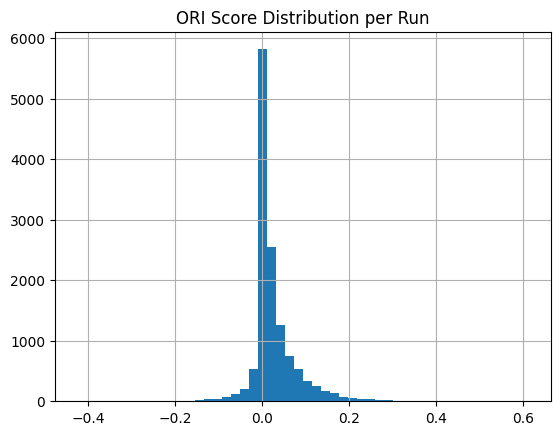

In [124]:
team_wide_df['OBSO_added_team'].hist(bins=50)
plt.title("ORI Score Distribution per Run")

## Top Runs with highest OBSO

In [102]:

team_filtered_df = team_wide_df[team_wide_df['team_name'] == 'Atletico Madrid']

team_filtered_df.sort_values(by='OBSO_added_team', ascending=False).tail(20)


,match_id,run_id,player_id,team_id_x,period,xR_added_team,PC_added_team,xG_added_team,OBSO_added_team,team_id_y,plyr_name,team_name,season_id,season_name,plyr_position
46,622092,622092_406,81666,1,2,-0.559,-0.755,-0.203,-0.047573,1.0,Jose Gimenez,Atletico Madrid,817531.0,ESP I 2024,DC
3543,622193,622193_168,1287803,1,1,-0.048,0.041,-0.084,-0.049638,1.0,Conor Gallagher,Atletico Madrid,817531.0,ESP I 2024,MC
7677,622275,622275_426,1295885,1,2,1.540,1.242,-0.157,-0.051281,1.0,Samuel Lino,Atletico Madrid,817531.0,ESP I 2024,ML
5178,622231,622231_243,191151,1,1,0.270,-1.012,-0.032,-0.052749,1.0,Marcos Llorente,Atletico Madrid,817531.0,ESP I 2024,DR
47,622092,622092_407,14,1,2,-0.338,-0.139,-0.176,-0.059139,1.0,Koke,Atletico Madrid,817531.0,ESP I 2024,MC
1453,622142,622142_452,20,1,2,0.448,0.228,0.249,-0.059764,1.0,Antoine Griezmann,Atletico Madrid,817531.0,ESP I 2024,FW
5209,622231,622231_466,14,1,2,-0.690,-0.819,0.437,-0.064735,1.0,Koke,Atletico Madrid,817531.0,ESP I 2024,MC
4539,622218,622218_44,138087,1,1,-0.890,0.504,-0.394,-0.068633,1.0,Axel Witsel,Atletico Madrid,817531.0,ESP I 2024,DC
3542,622193,622193_165,81666,1,1,-0.378,0.127,-0.081,-0.071656,1.0,Jose Gimenez,Atletico Madrid,817531.0,ESP I 2024,DC
10764,622332,622332_189,1295885,1,1,-0.287,-1.220,0.273,-0.072617,1.0,Samuel Lino,Atletico Madrid,817531.0,ESP I 2024,ML


In [103]:
team_filtered_df[team_filtered_df['OBSO_added_team'] <0.01]

,match_id,run_id,player_id,team_id_x,period,xR_added_team,PC_added_team,xG_added_team,OBSO_added_team,team_id_y,plyr_name,team_name,season_id,season_name,plyr_position
34,622092,622092_79,138087,1,1,0.219,0.521,0.002,-0.003605,1.0,Axel Witsel,Atletico Madrid,817531.0,ESP I 2024,DC
35,622092,622092_88,138087,1,1,1.342,-1.741,-0.008,-0.003522,1.0,Axel Witsel,Atletico Madrid,817531.0,ESP I 2024,DC
38,622092,622092_135,138087,1,1,0.053,1.538,-0.014,-0.002171,1.0,Axel Witsel,Atletico Madrid,817531.0,ESP I 2024,DC
39,622092,622092_144,20,1,1,-0.160,-0.149,0.000,0.000000,1.0,Antoine Griezmann,Atletico Madrid,817531.0,ESP I 2024,FW
40,622092,622092_237,138087,1,1,-0.125,0.868,-0.031,-0.000703,1.0,Axel Witsel,Atletico Madrid,817531.0,ESP I 2024,DC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12651,638260,638260_144,1248287,1,1,0.051,-0.219,0.000,0.000000,1.0,Robin Le Normand,Atletico Madrid,817531.0,ESP I 2024,DC
12655,638260,638260_229,14,1,2,-0.382,0.278,0.000,0.000000,1.0,Koke,Atletico Madrid,817531.0,ESP I 2024,MC
12656,638260,638260_234,81666,1,2,-0.414,-0.501,0.000,0.000000,1.0,Jose Gimenez,Atletico Madrid,817531.0,ESP I 2024,DC
12657,638260,638260_237,1242412,1,2,-0.432,-0.091,0.000,0.000000,1.0,Julian Alvarez,Atletico Madrid,817531.0,ESP I 2024,FW


In [104]:
from stats.obso.run_detection.plot_run import PlotRun
match_id = 622311
pr = PlotRun(match_id)
pr.load_pitch_control()


In [105]:
run_id = "622311_254"
plot_run = None
for run in runs:
    if run['run_id'] == run_id:
        plot_run = run
        break


PLYR ID: 1341673 | TYPE: start
FEATURES: {'shooter_dir_x': 0.0, 'shooter_dir_y': 0.0, 'distance': 45.39920704153323, 'shot_time': 2395.22, 'shooter_coord.x': 38.88, 'shooter_coord.y': 57.44, 'goal_coord.x': 0, 'goal_coord.y': 34, 'theta1': 90.0, 'theta2': 90.0, 'goal_opening_angle': 9.22, 'dir_angle': 31.08496229161316, 'shooter_speed': 0.0, 'tm_count_5': 0, 'tm_count_10': 0, 'opp_count_2': 0, 'opp_count_5': 0, 'opp_count_10': 0, 'dist_shooter_sideline': 38.88, 'num_opp2plyr_goal_shooter': 5, 'dist_shooter_goal': 45.39920704153323, 'dist_opponent_shooter': 12.33551782455848, 'opp_in_corridor_count': 1, 'dist2offside': 28.25, 'offside': False}
PLYR ID: 81666 | TYPE: start
FEATURES: {'shooter_dir_x': -0.05999999999999517, 'shooter_dir_y': -0.03999999999999915, 'distance': 51.26396004992202, 'shot_time': 2395.22, 'shooter_coord.x': 51.2, 'shooter_coord.y': 31.44, 'goal_coord.x': 0, 'goal_coord.y': 34, 'theta1': 36.55247275209311, 'theta2': 143.44752724790692, 'goal_opening_angle': 8.17, '

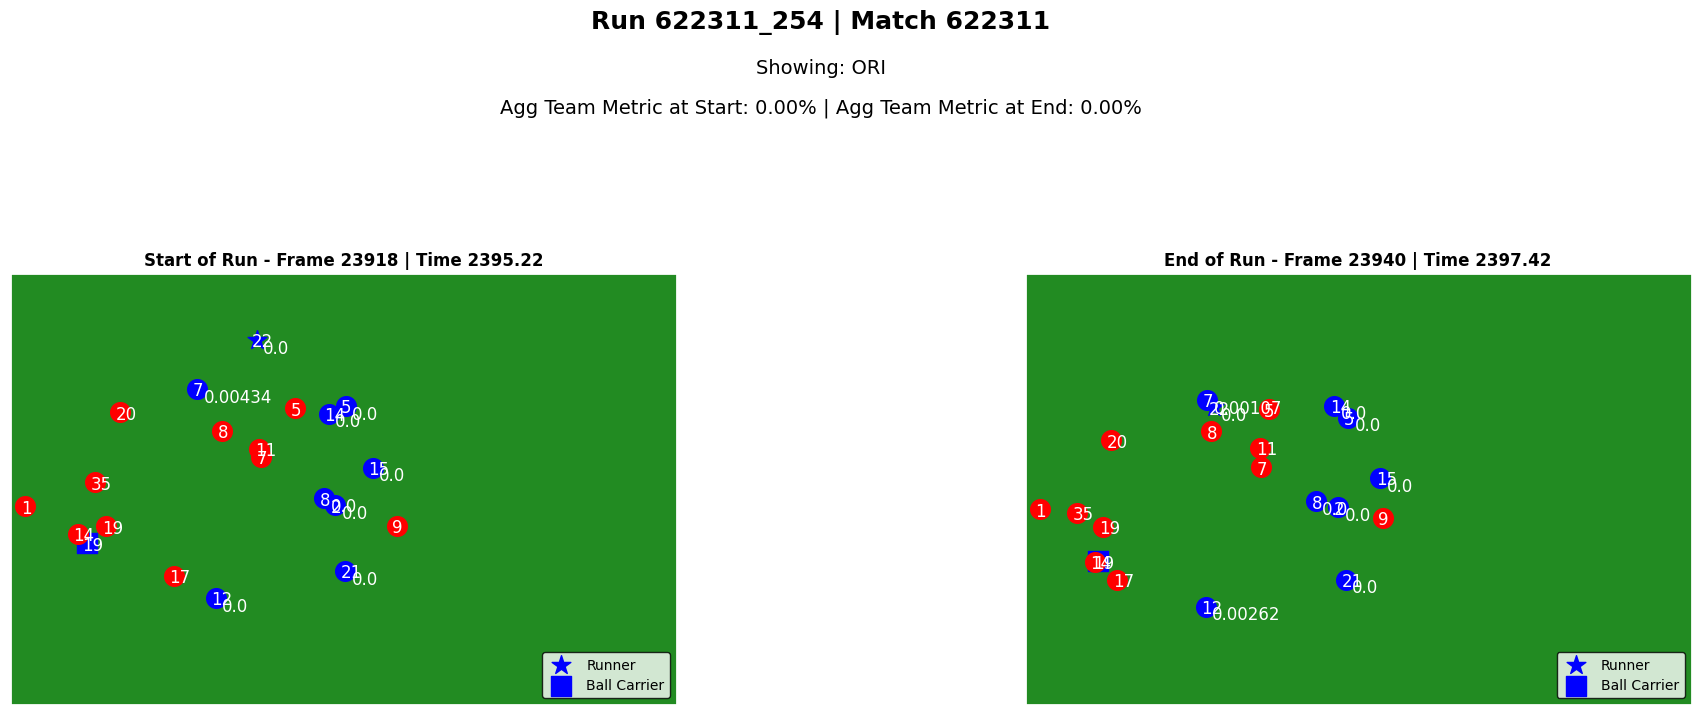

In [106]:
fig = pr.plot_run(plot_run, show_PC = False, show_xR = False, show_xG = False, show_ORI = True)

## Aggregate sum OBSO added team by Player

In [107]:
agg_OBSO_team = team_wide_df.groupby('player_id')['OBSO_added_team'].sum().reset_index()

agg_OBSO_team = agg_OBSO_team.sort_values(by='OBSO_added_team', ascending=False)

# Merge with run counts
agg_OBSO_team = agg_OBSO_team.merge(run_counts, on='player_id', how='left')



# Filter out players with less than 10 runs
agg_OBSO_team = agg_OBSO_team[agg_OBSO_team['run_count'] >= 30]


agg_OBSO_team.head(15)



,player_id,OBSO_added_team,run_count,team_id,plyr_name,team_name,season_id,season_name,plyr_position
0,191594,5.523254,123,4270.0,Inaki Williams,Athletic Club,817531.0,ESP I 2024,AMR
1,1216616,4.364919,161,4279.0,Raphinha,FC Barcelona,817531.0,ESP I 2024,AML
2,1155227,4.108677,113,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
3,69936,3.713626,101,4279.0,Robert Lewandowski,FC Barcelona,817531.0,ESP I 2024,FW
4,1242412,3.707203,88,1.0,Julian Alvarez,Atletico Madrid,817531.0,ESP I 2024,FW
5,20,3.685466,101,1.0,Antoine Griezmann,Atletico Madrid,817531.0,ESP I 2024,FW
6,1533082,3.665439,100,4270.0,Nico Williams,Athletic Club,817531.0,ESP I 2024,AML
7,1158830,3.560741,104,4270.0,Alex Berenguer,Athletic Club,817531.0,ESP I 2024,AMC
8,1171076,3.529657,96,2.0,Hugo Duro,Valencia,817531.0,ESP I 2024,FW
9,163093,3.338133,80,61409.0,Kike Garcia,Deportivo Alaves,817531.0,ESP I 2024,FW


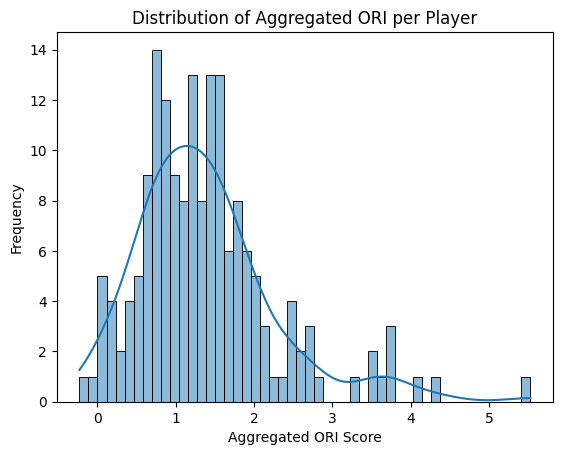

In [108]:
sns.histplot(agg_OBSO_team['OBSO_added_team'], bins=50, kde=True)
plt.xlabel("Aggregated ORI Score")
plt.ylabel("Frequency")
plt.title("Distribution of Aggregated ORI per Player")
plt.show()

## Aggregate avg OBSO added team by Player

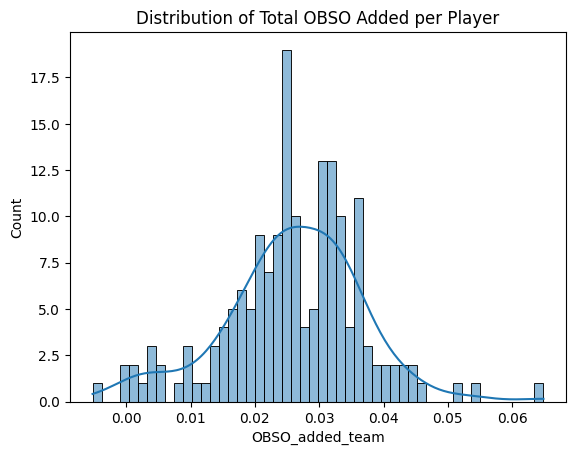

In [109]:
avg_OBSO_team = team_wide_df.groupby('player_id')['OBSO_added_team'].mean().reset_index()

avg_OBSO_team = avg_OBSO_team.sort_values(by='OBSO_added_team', ascending=False)

# Merge with run counts
avg_OBSO_team = avg_OBSO_team.merge(run_counts, on='player_id', how='left')



# Filter out players with less than 10 runs
avg_OBSO_team = avg_OBSO_team[avg_OBSO_team['run_count'] >= 30]

avg_OBSO_team.head(20)

sns.histplot(avg_OBSO_team['OBSO_added_team'], bins=50, kde=True)
plt.title("Distribution of Total OBSO Added per Player")
plt.show()

## Get Player Specific OBSO

In [110]:
mbappe_df = team_wide_df[team_wide_df['player_id'] == 1155227]

# Sort by OBSO added team
mbappe_df = mbappe_df.sort_values(by='OBSO_added_team', ascending=False)

# Sum OBSO added team
mbappe_df['OBSO_added_team'].sum()

4.1086773095925

In [111]:
mbappe_df.head(10)

,match_id,run_id,player_id,team_id_x,period,xR_added_team,PC_added_team,xG_added_team,OBSO_added_team,team_id_y,plyr_name,team_name,season_id,season_name,plyr_position
7825,622278,622278_293,1155227,4265,2,-0.921,1.894,1.011,0.449529,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
11588,622345,622345_333,1155227,4265,2,0.087,0.706,0.830,0.264792,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
7782,622278,622278_118,1155227,4265,1,0.626,1.694,0.445,0.204724,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
9225,622300,622300_338,1155227,4265,2,-0.154,-1.415,0.610,0.195717,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
7841,622278,622278_354,1155227,4265,2,-0.137,-0.058,0.622,0.180604,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
9243,622300,622300_432,1155227,4265,2,0.553,-0.092,0.418,0.175125,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
9603,622311,622311_346,1155227,4265,2,0.416,1.469,0.009,0.117509,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
9650,622311,622311_544,1155227,4265,2,0.584,0.015,0.301,0.113845,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
9626,622311,622311_432,1155227,4265,2,0.306,-1.724,0.386,0.113303,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW
5049,622229,622229_319,1155227,4265,2,-0.463,0.700,0.413,0.110615,4265.0,Kylian Mbappe,Real Madrid,817531.0,ESP I 2024,FW


## Aggregate OBSO by position

In [112]:
# Group by position and sum OBSO
agg_OBSO_position = agg_OBSO_team.groupby('plyr_position')['OBSO_added_team'].sum().reset_index()

# Get the count of players per position
position_counts = agg_OBSO_team['plyr_position'].value_counts().reset_index()
position_counts.columns = ['plyr_position', 'count']

# Merge sum and count
agg_OBSO_position = agg_OBSO_position.merge(position_counts, on='plyr_position')

# Sort by OBSO added
agg_OBSO_position = agg_OBSO_position.sort_values(by='OBSO_added_team', ascending=False)
agg_OBSO_position


,plyr_position,OBSO_added_team,count
9,FW,66.853567,38
0,AMC,22.596830,13
12,MC,22.519347,23
14,MR,21.404800,14
8,DR,20.789312,18
4,DL,17.723881,14
1,AML,15.939622,7
2,AMR,15.866146,7
13,ML,11.595419,8
3,DC,5.873703,17


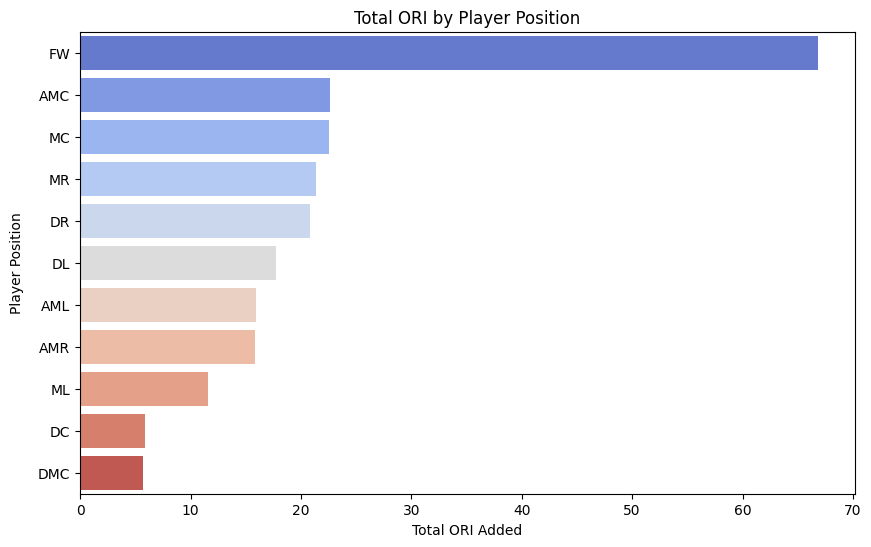

In [113]:
# agg_OBSO_position = agg_OBSO_team.groupby('plyr_position')['OBSO_added_team'].sum().reset_index()

# agg_OBSO_position = agg_OBSO_position.sort_values(by='OBSO_added_team', ascending=False)

# filter with more than 5 players per position

agg_OBSO_position = agg_OBSO_position[agg_OBSO_position['count'] >= 5]

# Create a bar chart
plt.figure(figsize=(10, 6))
sns.barplot(data=agg_OBSO_position, x='OBSO_added_team', y='plyr_position', palette='coolwarm', hue='plyr_position')
plt.title('Total ORI by Player Position')
plt.xlabel('Total ORI Added')
plt.ylabel('Player Position', labelpad=10)
plt.show()

## Visualize OBSO vs Run Count

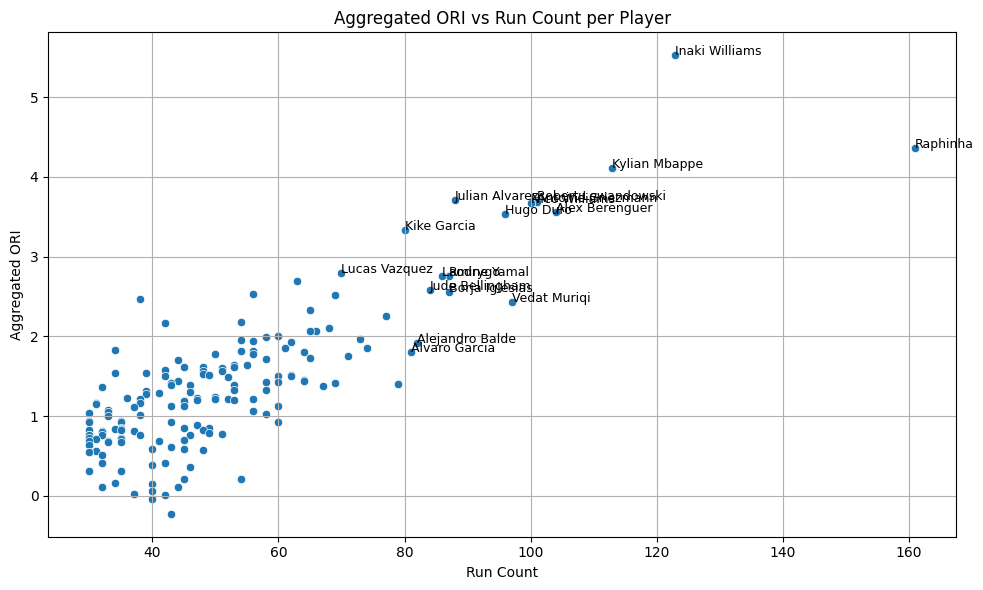

In [116]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=agg_OBSO_team, x='run_count', y='OBSO_added_team')

# Filter players with more than 1 OBSO and more than 100 runs
filtered_players = agg_OBSO_team[(agg_OBSO_team['OBSO_added_team'] > 2.7) | (agg_OBSO_team['run_count'] > 80)]

# Annotate player names
for i in range(filtered_players.shape[0]):
    plt.text(filtered_players['run_count'].iloc[i], 
             filtered_players['OBSO_added_team'].iloc[i], 
             filtered_players['plyr_name'].iloc[i], 
             fontsize=9)

plt.title('Aggregated ORI vs Run Count per Player')
plt.xlabel('Run Count')
plt.ylabel('Aggregated ORI')
plt.grid(True)
plt.tight_layout()
plt.show()


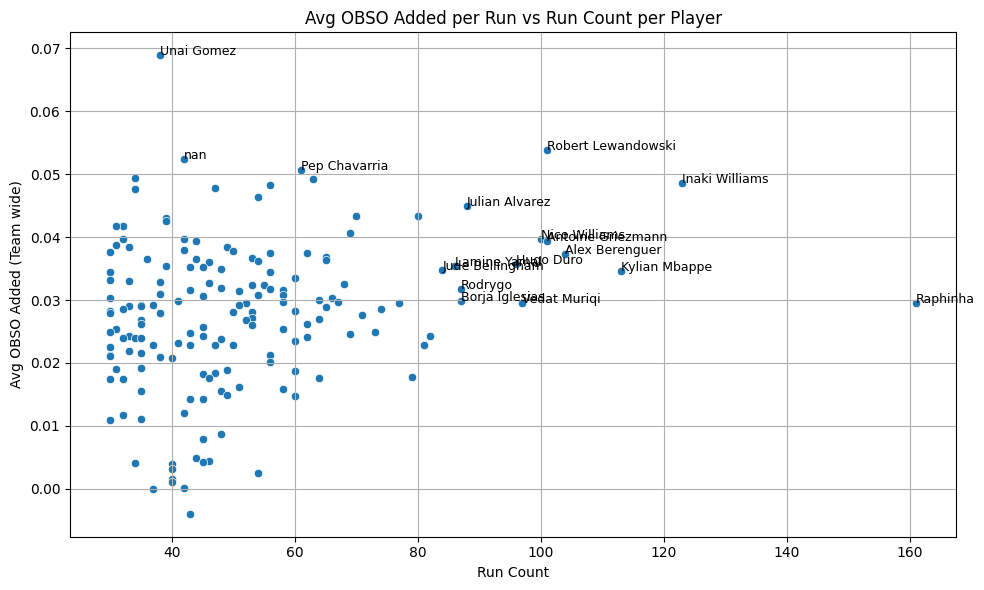

In [316]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=avg_OBSO_team, x='run_count', y='OBSO_added_team')

# Filter players with more than 1 OBSO and more than 100 runs
filtered_players = avg_OBSO_team[(avg_OBSO_team['OBSO_added_team'] > 0.05) | (avg_OBSO_team['run_count'] > 82)]

# Annotate player names
for i in range(filtered_players.shape[0]):
    plt.text(filtered_players['run_count'].iloc[i], 
             filtered_players['OBSO_added_team'].iloc[i], 
             filtered_players['plyr_name'].iloc[i], 
             fontsize=9)

plt.title('Avg OBSO Added per Run vs Run Count per Player')
plt.xlabel('Run Count')
plt.ylabel('Avg OBSO Added (Team wide)')
plt.grid(True)
plt.tight_layout()
plt.show()


## Normalize OBSO

In [226]:
agg_OBSO_team['OBSO_per_run'] = agg_OBSO_team['OBSO_added_team'] / agg_OBSO_team['run_count']
top_eff = agg_OBSO_team.sort_values(by='OBSO_per_run', ascending=False).head(20)

top_eff[['plyr_name', 'team_name', 'run_count', 'OBSO_added_team', 'OBSO_per_run']]


,plyr_name,team_name,run_count,OBSO_added_team,OBSO_per_run
4,Pep Chavarria,Rayo Vallecano,61,9.9873,0.163726
22,Fermin Lopez,FC Barcelona,34,5.5191,0.162326
24,Javi Galan,Atletico Madrid,39,5.4652,0.140133
43,Pablo Fornals,Real Betis,34,4.6499,0.136762
0,Robert Lewandowski,FC Barcelona,101,13.2717,0.131403
34,Unai Gomez,Athletic Club,38,4.9881,0.131266
70,Andre Almeida,Valencia,30,3.7855,0.126183
25,Hugo Álvarez,Celta de Vigo,43,5.4204,0.126056
20,Orri Oskarsson,Real Sociedad,48,6.0426,0.125887
63,Ayoze Perez,Villarreal,31,3.8964,0.125690


## Team-level aggregation

In [117]:
# Load t_team_data
t_team_data = pd.read_csv("/Users/svasquez/AWS_PC/t_team_top5_leagues.csv")



In [118]:
team_OBSO = agg_OBSO_team.groupby('team_id').agg({'OBSO_added_team': 'sum', 'team_id': 'count'}).rename(columns={'team_id': 'row_count'}).reset_index()
team_OBSO

# # Merge with t_team_data
team_OBSO = team_OBSO.merge(t_team_data, on='team_id', how='left')

team_OBSO

,team_id,OBSO_added_team,row_count,team_name
0,1.0,18.996316,12,Atletico Madrid
1,2.0,8.168608,6,Valencia
2,4263.0,19.182580,14,Celta de Vigo
3,4264.0,6.153726,5,Espanyol
4,4265.0,19.986891,9,Real Madrid
5,4266.0,12.519218,9,Real Betis
6,4267.0,6.218854,9,Osasuna
7,4269.0,11.242237,8,Valladolid
8,4270.0,19.461906,7,Athletic Club
9,4272.0,9.084842,9,Villarreal


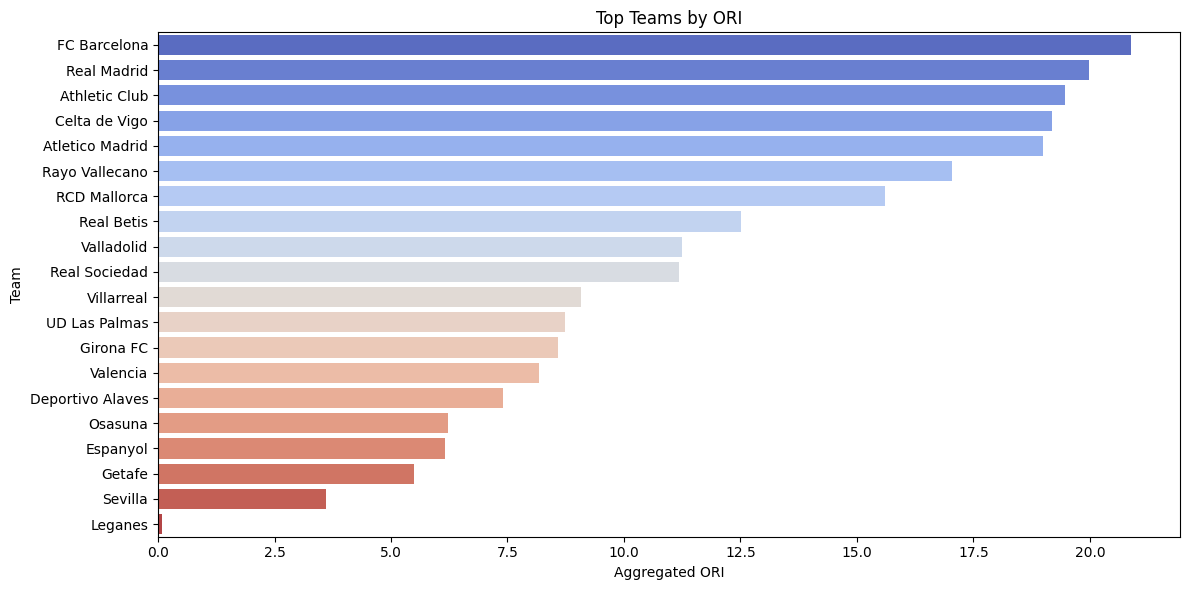

In [119]:

team_OBSO = team_OBSO.sort_values(by='OBSO_added_team', ascending=False)

# filter teams 
remove_team_ids  = [69854.0, 62071.0]

team_OBSO = team_OBSO[~team_OBSO['team_id'].isin(remove_team_ids)]

plt.figure(figsize=(12, 6))
sns.barplot(data=team_OBSO, x='OBSO_added_team', y='team_name', palette='coolwarm', hue = 'team_name')
plt.title('Top Teams by ORI')
plt.xlabel('Aggregated ORI')
plt.ylabel('Team')
plt.tight_layout()
plt.show()


## Validate with xG

In [120]:
xG_laliga = pd.read_csv("/Users/svasquez/AWS_PC/xG_laliga.csv")


KPI_laliga = "/Users/svasquez/AWS_PC/KPIs_laliga.csv"

KPI_laliga = pd.read_csv(KPI_laliga)

KPI_laliga.head()






,player_id,xg,name,xt,goals,assists,contributions
0,66,17.305464,Best Forward,10.5695,25.0,6.0,31.0
1,69936,17.305464,Robert Lewandowski,2.5749,25.0,2.0,27.0
2,1155227,14.060273,Kylian Mbappe,9.1143,22.0,3.0,25.0
3,1759377,11.970783,Thierno Barry,1.5305,10.0,2.0,12.0
4,1159148,10.849174,Ante Budimir,1.6474,18.0,1.0,19.0


In [121]:
KPI_laliga_agg = agg_OBSO_team.merge(KPI_laliga, on = 'player_id', how = 'left')
    
KPI_laliga_agg.columns


Index(['player_id', 'OBSO_added_team', 'run_count', 'team_id', 'plyr_name',
       'team_name', 'season_id', 'season_name', 'plyr_position', 'xg', 'name',
       'xt', 'goals', 'assists', 'contributions'],
      dtype='object')

In [122]:
# Select KPIs
kpi_cols = ['xg', 'xt', 'goals', 'assists', 'contributions']

# Compute correlation of ORI (OBSO_added_team) with each KPI
corr_with_ori = KPI_laliga_agg[['OBSO_added_team'] + kpi_cols].corr().loc['OBSO_added_team', kpi_cols]

# Create a DataFrame for the table
corr_table = corr_with_ori.reset_index()
corr_table.columns = ['KPI', 'Correlation with ORI']

# Sort values if you want (optional)
corr_table = corr_table.sort_values(by='Correlation with ORI', ascending=False)

# Display
corr_table


,KPI,Correlation with ORI
4,contributions,0.603206
0,xg,0.557752
2,goals,0.509943
3,assists,0.472813
1,xt,0.349578


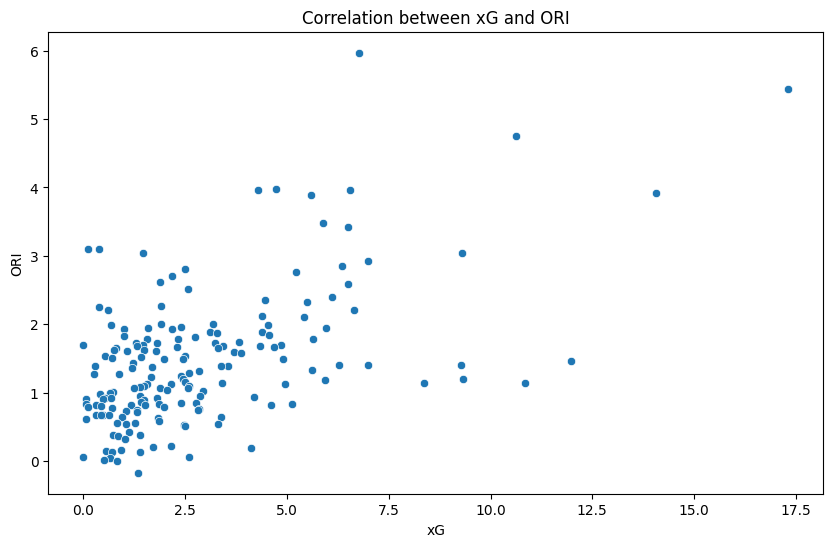

In [422]:

# TEst correlation between xG and ORI

plt.figure(figsize=(10, 6))
sns.scatterplot(data=KPI_laliga_agg, x='xg', y='OBSO_added_team')
plt.title('Correlation between xG and ORI')
plt.xlabel('xG')
plt.ylabel('ORI')
plt.show()


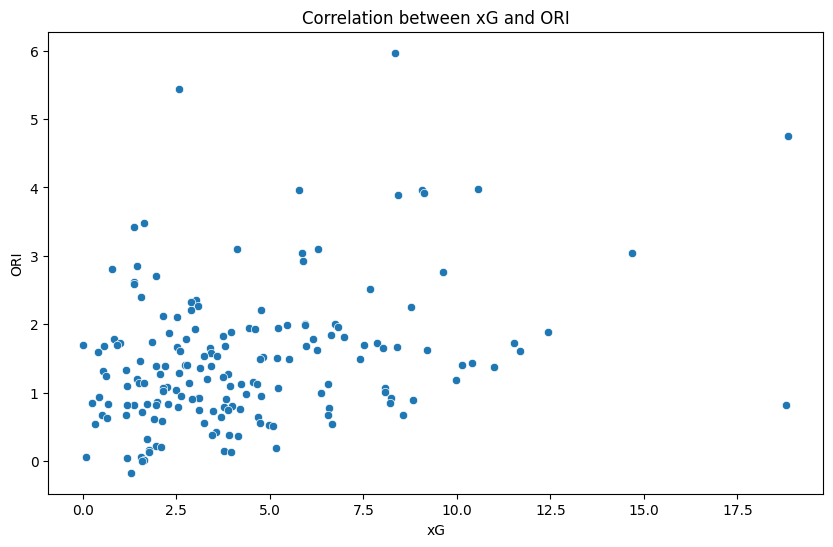

In [420]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=KPI_laliga_agg, x='xt', y='OBSO_added_team')
plt.title('Correlation between xG and ORI')
plt.xlabel('xG')
plt.ylabel('ORI')
plt.show()


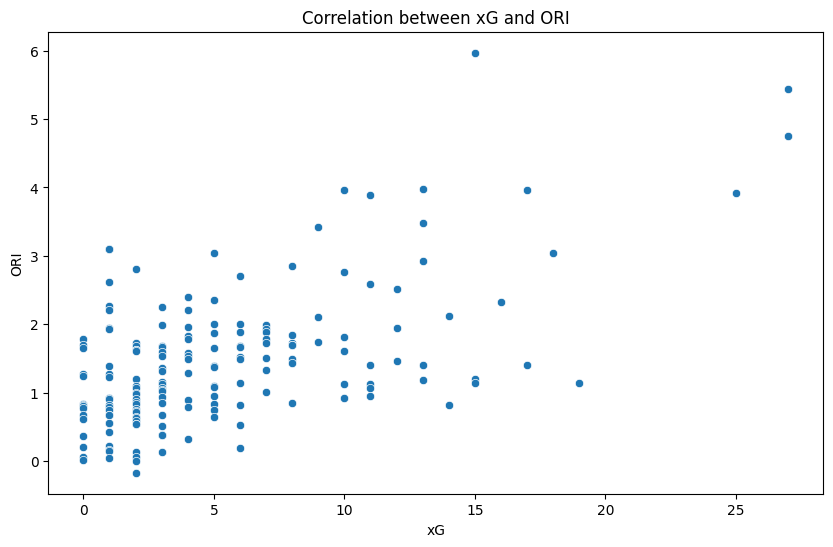

In [421]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=KPI_laliga_agg, x='contributions', y='OBSO_added_team')
plt.title('Correlation between xG and ORI')
plt.xlabel('xG')
plt.ylabel('ORI')
plt.show()


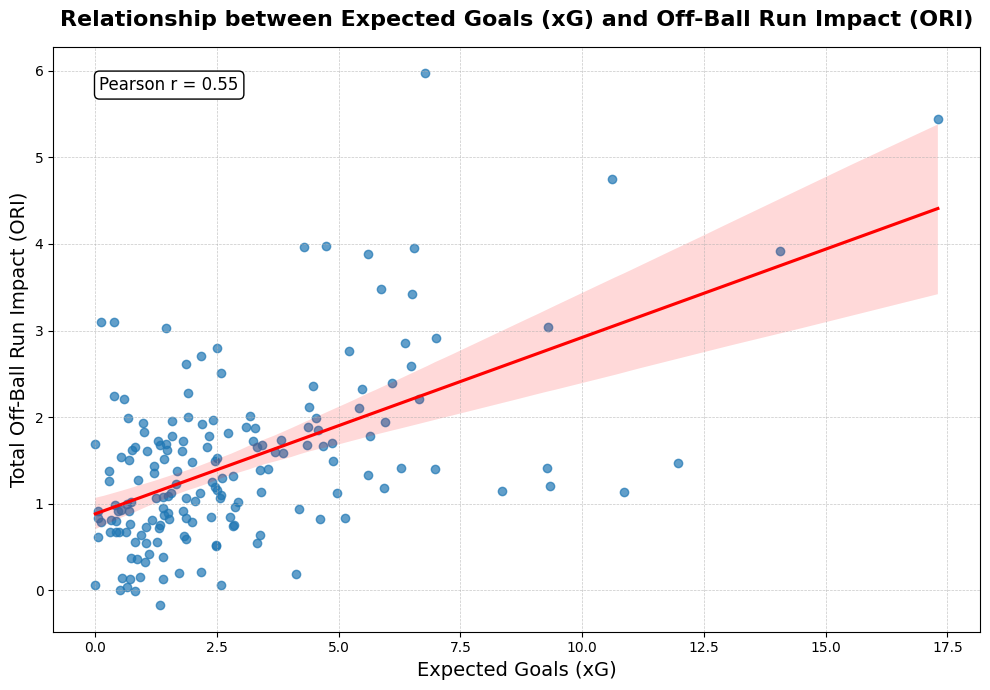

In [417]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# Calculate correlation
corr, p_value = pearsonr(xG_laliga_agg['xg'], xG_laliga_agg['OBSO_added_team'])

plt.figure(figsize=(10, 7))
sns.regplot(data=xG_laliga_agg, x='xg', y='OBSO_added_team', scatter_kws={'alpha':0.7}, line_kws={"color":"red"})
plt.title('Relationship between Expected Goals (xG) and Off-Ball Run Impact (ORI)', fontsize=16, weight='bold', pad=15)
plt.xlabel('Expected Goals (xG)', fontsize=14)
plt.ylabel('Total Off-Ball Run Impact (ORI)', fontsize=14)
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

# Annotate correlation coefficient
plt.text(0.05, 0.95, f'Pearson r = {corr:.2f}', transform=plt.gca().transAxes, fontsize=12, verticalalignment='top', bbox=dict(boxstyle="round,pad=0.3", edgecolor='black', facecolor='white'))

plt.tight_layout()
plt.show()


# Plot Runs

In [36]:
from stats.obso.run_detection.plot_run import PlotRun
match_id = 622593
    
pr = PlotRun(match_id)

pr.load_pitch_control()



ModuleNotFoundError: No module named 'xReceiver'

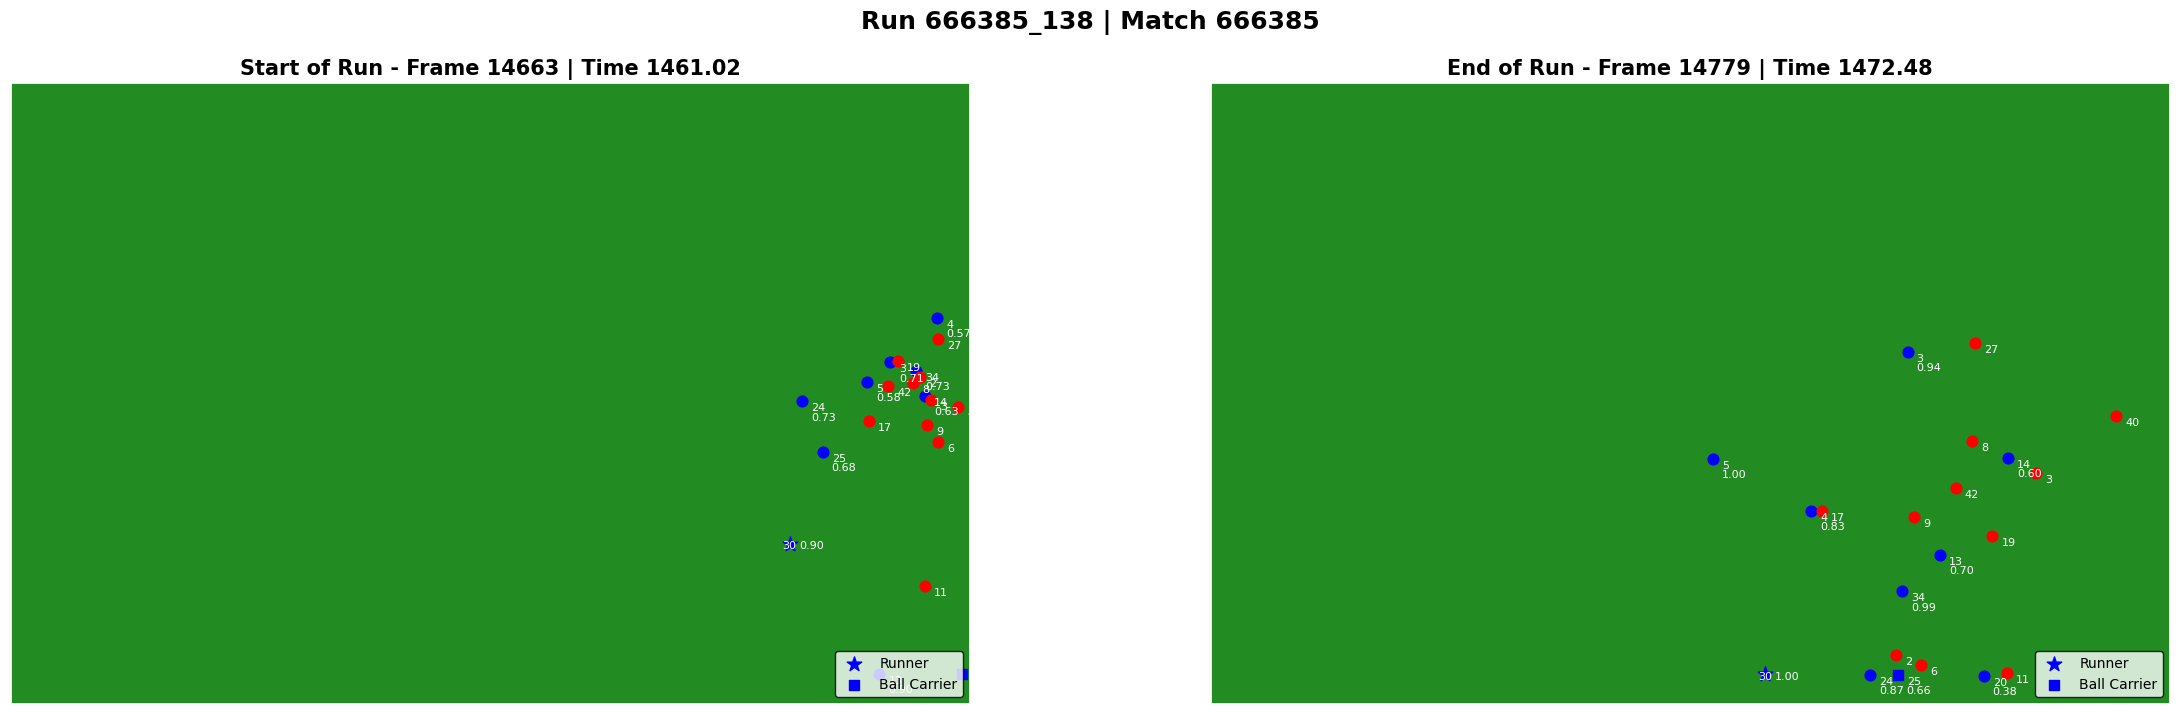

In [35]:


run_id = 138
fig = pr.plot_run(pr.runs[run_id], pr.player_lookup, pc_annotate = True, def_team = True)
plt.show()

# Calculate Raw OBSO

In [38]:
def calc_raw_obso(xR, PC, xG):
    return xR * PC * (xG **1)



team_wide_obso = []
for run in runs:

    team_wide_OBSO_start = 0
    team_wide_OBSO_end = 0

    # Calculate raw OBSO for runner
    runner_OBSO_start = calc_raw_obso(run['runner_info']['metrics']['xR_start'], run['runner_info']['metrics']['PC_start'], run['runner_info']['metrics']['xG_start'])
    runner_OBSO_end = calc_raw_obso(run['runner_info']['metrics']['xR_end'], run['runner_info']['metrics']['PC_end'], run['runner_info']['metrics']['xG_end'])

    team_wide_OBSO_start += runner_OBSO_start
    team_wide_OBSO_end += runner_OBSO_end

    run['runner_info']['metrics']['OBSO_start'] = runner_OBSO_start
    run['runner_info']['metrics']['OBSO_end'] = runner_OBSO_end
    run['runner_info']['metrics']['OBSO_delta'] = runner_OBSO_end - runner_OBSO_start

    # Calculate raw OBSO for all teammates
    for teammate in run['off_ball_teammates']:
        teammate_OBSO_start = calc_raw_obso(teammate['metrics']['xR_start'], teammate['metrics']['PC_start'], teammate['metrics']['xG_start'])
        teammate_OBSO_end = calc_raw_obso(teammate['metrics']['xR_end'], teammate['metrics']['PC_end'], teammate['metrics']['xG_end'])
        teammate_OBSO_delta = teammate_OBSO_end - teammate_OBSO_start

        teammate['metrics']['OBSO_start'] = teammate_OBSO_start
        teammate['metrics']['OBSO_end'] = teammate_OBSO_end
        teammate['metrics']['OBSO_delta'] = teammate_OBSO_delta

        team_wide_OBSO_start += teammate_OBSO_start
        team_wide_OBSO_end += teammate_OBSO_end

    run['team_wide_OBSO_start'] = team_wide_OBSO_start
    run['team_wide_OBSO_end'] = team_wide_OBSO_end

    team_wide_OBSO_delta = team_wide_OBSO_end - team_wide_OBSO_start
    run['team_wide_OBSO_delta'] = team_wide_OBSO_delta

    team_wide_obso.append({
        'match_id': run['match_id'],
        'run_id': run['run_id'],
        'team_id': run['team_id'],
        'OBSO_delta': team_wide_OBSO_delta
    })



In [39]:
print(len(team_wide_obso))

14352


In [40]:
# Get average OBSO metrics
avg_team_wide_obso = pd.DataFrame(team_wide_obso)
avg_team_wide_obso['OBSO_delta'].mean()



0.008453401540592043

## Get teh average OBSO metrics

In [41]:
# Make DF of OBSO metrics
obso_metrics = []

for run in runs:
    # Get runner metrics
    runner_metrics = {
        'match_id': run['match_id'],
        'run_id': run['run_id'],
        'team_id': run['team_id'],
        'player_id': run['player_id'],
        'start_frame': run['start_frame'],
        'end_frame': run['end_frame'],
        'period': run['period'],
        'is_runner': True,
        'team_wide_OBSO_delta' : run['team_wide_OBSO_delta']

    }
    obso_metrics.append(runner_metrics)
    
# Convert to DataFrame
obso_df = pd.DataFrame(obso_metrics)

obso_df = obso_df.sort_values(by='team_wide_OBSO_delta', ascending=False)
obso_df

,match_id,run_id,team_id,player_id,start_frame,end_frame,period,is_runner,team_wide_OBSO_delta
8600,622278,622278_366,4265,1296920,58654,58757,2,True,0.778226
7304,622254,622254_497,4265,1169460,59486,59508,2,True,0.765230
322,622100,622100_95,61410,1295867,16946,17025,1,True,0.577394
2117,622152,622152_527,4272,151879,57470,57560,2,True,0.574267
805,622121,622121_499,61410,1295824,57306,57410,2,True,0.560204
...,...,...,...,...,...,...,...,...,...
13383,622359,622359_46,4272,1237127,4472,4490,1,True,-0.371507
12853,622348,622348_346,1,1261183,51080,51135,2,True,-0.391703
8490,622276,622276_448,4265,1509464,56084,56255,2,True,-0.393253
8722,622280,622280_919,20079,1158747,54264,54292,2,True,-0.442756


In [43]:
# Grouping by 'player_id' and summing 'team_wide_OBSO_delta'
grouped_df = obso_df.groupby('player_id')['team_wide_OBSO_delta'].mean().reset_index()

# Sort by team_wide_OBSO_delta
grouped_df = grouped_df.sort_values(by='team_wide_OBSO_delta', ascending=False)


# Join with t_player_data
t_player_data = pd.read_csv("/Users/svasquez/AWS_PC/t_player_data.csv")

grouped_df = grouped_df.merge(t_player_data, on='player_id', how='left')
grouped_df.head(20)
# # Merge with run counts

# grouped_df = grouped_df.merge(run_counts, on='player_id', how='left')

# # get onoy playes that have at least 10 runs
# grouped_df = grouped_df[grouped_df['run_count'] >= 10]

# grouped_df.head(20)


,player_id,team_wide_OBSO_delta,name,team_id
0,1295867,0.577394,NaN,NaN
1,347,0.424291,NaN,NaN
2,39058,0.219642,NaN,NaN
3,1159993,0.165064,NaN,NaN
4,1704990,0.152964,NaN,NaN
5,1433989,0.132725,NaN,NaN
6,1686405,0.119818,NaN,NaN
7,1217637,0.104437,NaN,NaN
8,189963,0.104168,NaN,NaN
9,1267506,0.101520,NaN,NaN


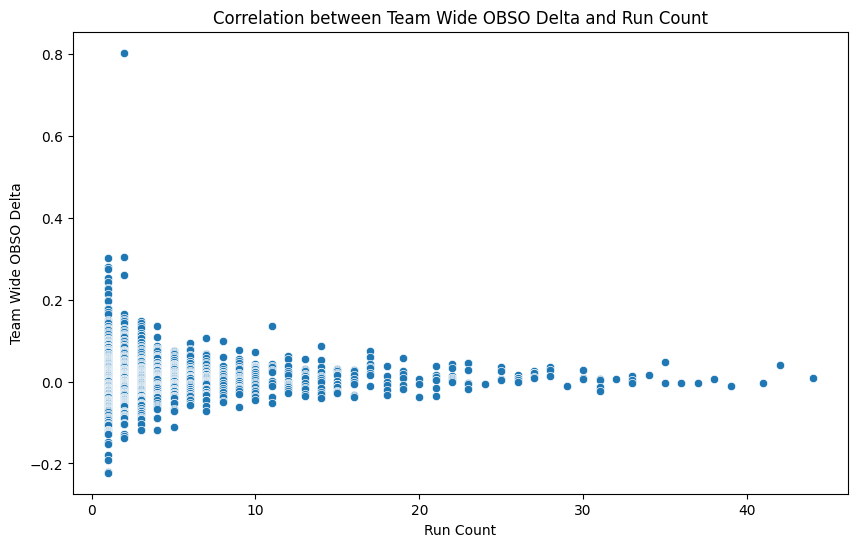

In [173]:
# plot corr between team_wide_OBSO_delta and run_count
plt.figure(figsize=(10, 6))
sns.scatterplot(data=grouped_df, x='run_count', y='team_wide_OBSO_delta')
plt.title('Correlation between Team Wide OBSO Delta and Run Count')
plt.xlabel('Run Count')
plt.ylabel('Team Wide OBSO Delta')
plt.show()

## Get the OBSO delta by Runner

In [177]:
# Make DF of OBSO metrics
obso_metrics_runner = []

for run in runs:
    

    
    # Get runner metrics
    runner_metrics = {
        'match_id': run['match_id'],
        'run_id': run['run_id'],
        'team_id': run['team_id'],
        'player_id': run['player_id'],
        'start_frame': run['start_frame'],
        'end_frame': run['end_frame'],
        'period': run['period'],
        'is_runner': True,
        'OBSO_delta' : run['runner_info']['metrics']['OBSO_delta']

    }
    obso_metrics_runner.append(runner_metrics)
    
# Convert to DataFrame
obso_runner_df = pd.DataFrame(obso_metrics_runner)
obso_runner_df

,match_id,run_id,team_id,player_id,start_frame,end_frame,period,is_runner,OBSO_delta
0,622555,622555_14,12,1248525,648,676,1,True,0.006111
1,622555,622555_15,12,1281301,668,686,1,True,-0.026609
2,622555,622555_17,12,1304950,744,760,1,True,0.014945
3,622555,622555_39,12,1733126,3452,3466,1,True,-0.016101
4,622555,622555_41,12,1732978,3462,3486,1,True,0.025237
...,...,...,...,...,...,...,...,...,...
6556,666385,666385_404,3651,1329659,51920,51962,2,True,-0.005443
6557,666385,666385_432,3651,69700,54954,54968,2,True,-0.008195
6558,666385,666385_436,3659,1322737,55386,55406,2,True,0.012872
6559,666385,666385_437,3659,1159149,55388,55408,2,True,-0.014522


In [179]:
# Grouping by 'player_id' and summing 'team_wide_OBSO_delta'
grouped_df_runner = obso_runner_df.groupby('player_id')['OBSO_delta'].sum().reset_index()

# Sort by team_wide_OBSO_delta
grouped_df_runner = grouped_df_runner.sort_values(by='OBSO_delta', ascending=False)


# Join with t_player_data
t_player_data = pd.read_csv("/Users/svasquez/AWS_PC/t_player_data.csv")

grouped_df_runner = grouped_df_runner.merge(t_player_data, on='player_id', how='left')

# Merge with run counts

grouped_df_runner = grouped_df_runner.merge(run_counts, on='player_id', how='left')

# get onoy playes that have at least 10 runs
grouped_df_runner = grouped_df_runner[grouped_df_runner['run_count'] >= 10]

grouped_df_runner.head(20)

,player_id,OBSO_delta,name_x,team_id_x,run_count,name_y,team_id_y
1,1242415,0.296074,Jan Paul Van Hecke,2019,12,Jan Paul Van Hecke,2019
2,41349,0.257204,Dan Burn,1932,17,Dan Burn,1932
3,1301778,0.255186,Levi Colwill,1930,14,Levi Colwill,1930
5,1155313,0.226165,Christopher Nkunku,1930,22,Christopher Nkunku,1930
6,1157172,0.215298,Alexander Isak,1932,22,Alexander Isak,1932
8,240037,0.198506,Fabian Schar,1932,15,Fabian Schar,1932
19,1295026,0.133448,Martinelli,1928,35,Martinelli,1928
20,138606,0.130819,Bernardo Silva,1939,30,Bernardo Silva,1939
21,1158367,0.121711,Aaron Wan Bissaka,1948,10,Aaron Wan Bissaka,1948
22,1619221,0.119149,Kobbie Mainoo,1946,13,Kobbie Mainoo,1946
